# Unsupervised Learning: Clustering and Manifold Learning in Depth

> **Who is this for:** you have used `KMeans` or `DBSCAN` from sklearn (see [`01_clustering`](01_clustering.ipynb)) and PCA/t-SNE (see [`02_dimensionality_reduction`](02_dimensionality_reduction.ipynb)), and now want to know exactly how they work, how to choose their settings, and how to tell a good clustering from a bad one. It is also exam and interview preparation for "Data Mining" and "Machine Learning" courses.
>
> **What you will learn:**
> - **K-means from scratch** (Lloyd's algorithm), **k-means++** seeding, empty clusters, **mini-batch k-means**, and their complexity
> - Choosing k: **elbow**, **silhouette**, **gap statistic** and **Davies–Bouldin**, each implemented and checked against sklearn
> - **Hierarchical clustering from scratch** (single, complete, average and Ward linkage via the Lance–Williams formula), checked against scipy, and how to read a dendrogram
> - **DBSCAN from scratch** (core / border / noise), OPTICS reachability plots and HDBSCAN
> - **Spectral clustering from scratch** (affinity graph → Laplacian → eigenvectors → k-means)
> - External metrics (**ARI, NMI, purity**) implemented, plus **bootstrap stability** analysis
> - Manifold learning: **FastICA** (the cocktail-party problem), classical **MDS**, **Isomap** and **LLE** from scratch on the swiss roll; **t-SNE perplexity pitfalls**; UMAP (optional)
> - **NMF** from scratch for parts-based representations of digits
> - A practical recipe: scaling, distance choice and high-dimensional pitfalls
>
> **Prerequisites:** [Python basics](../../01_Python/01_basic.ipynb); [linear algebra (eigenvectors)](../../14_Mathematics/01_linear_algebra.ipynb); [`01_clustering`](01_clustering.ipynb) and [`02_dimensionality_reduction`](02_dimensionality_reduction.ipynb). Graph basics help for Sections 5 and 7: [graph theory](../../14_Mathematics/discrete_math/03_graph_theory.ipynb).
>
> **Time needed:** about 3–4 hours.
>
> **Runs on:** CPU, no API key, no internet (all data is synthetic or ships with sklearn). The whole notebook runs in about a minute.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep. It follows Hastie, Tibshirani & Friedman, *The Elements of Statistical Learning* (ESL) ch. 14, and Tan, Steinbach, Karpatne & Kumar, *Introduction to Data Mining* ch. 7–8.

## Explained simply

**Clustering** means putting similar things into groups when nobody has told you what the groups are. Imagine tipping a big box of mixed LEGO bricks on the floor and sorting them into piles without instructions: by colour, by size, or by shape. Different sorting rules give different piles, and there is no single "right" answer, which is what makes clustering tricky. A supermarket does the same with customers: "weekend family shoppers", "late-night snack buyers", "bulk buyers", discovered from receipts alone.

**Manifold learning** is about drawing a faithful *map* of data that lives in many dimensions. A rolled-up poster is a flat 2-D sheet curled up in 3-D space; manifold learning tries to unroll it so that points that were close **along the poster** stay close on the map. A world map does the same for the curved surface of the Earth.

**Tiny example.** Six friends' heights in cm: 150, 152, 155, 180, 182, 185. Ask for 2 groups. K-means starts with two guesses, say 150 and 185, puts each friend with the nearer guess ({150, 152, 155} and {180, 182, 185}), moves each guess to its group's average (152.3 and 182.3), and checks again. Nobody changes group, so it stops.

**In one line**

| Concept | Simple meaning | Where you see it in real life/AI |
|---|---|---|
| Clustering | group similar items without labels | customer segments, grouping news stories, deduplicating training data |
| Cluster validation | checking whether the groups are real and stable | choosing the number of segments, comparing algorithms |
| Manifold learning | draw a 2-D map of high-dimensional data that keeps neighbours together | visualising word or image embeddings, single-cell biology maps |

### How this notebook is different from its neighbours
- [`01_clustering`](01_clustering.ipynb) introduces the algorithms mostly through sklearn calls. Here **every core algorithm is implemented from scratch** and checked against sklearn/scipy, and we add validation (gap statistic, stability, external metrics).
- [`02_dimensionality_reduction`](02_dimensionality_reduction.ipynb) covers PCA, t-SNE and UMAP usage. Here we build **ICA, MDS, Isomap, LLE and NMF** ourselves and show when t-SNE plots mislead.
- [`04_industry_customer_segmentation`](04_industry_customer_segmentation.ipynb) applies clustering to a business problem; this notebook gives you the theory to defend those choices.
- [`17_probabilistic_graphical_models/02`](../17_probabilistic_graphical_models/02_em_variational_inference_and_sampling.ipynb) derives EM for Gaussian mixtures (soft clustering).

## Table of contents
1. K-means from scratch: Lloyd, k-means++, empty clusters, mini-batch
2. Choosing k: elbow, silhouette, gap statistic, Davies–Bouldin
3. Hierarchical clustering from scratch
4. Density-based clustering: DBSCAN from scratch, OPTICS, HDBSCAN
5. Spectral clustering from scratch
6. External metrics (ARI, NMI, purity) and stability
7. Manifold learning: ICA, MDS, Isomap, LLE, t-SNE pitfalls
8. NMF: parts-based representations
9. A practical recipe: scaling, distances and high dimensions
10. Algorithm comparison table
11. How this connects to modern AI
12. Recap, practice problems, further reading

In [1]:
# Standard setup used throughout this notebook
import os
os.environ.setdefault("OMP_NUM_THREADS", "2")     # be polite on shared machines
os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")
import sys, math, time, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)
np.random.seed(42)

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.titleweight": "bold", "figure.dpi": 100,
})
pd.set_option("display.width", 140)
pd.set_option("display.precision", 4)
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)

from collections import deque
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.sparse.csgraph import shortest_path
from scipy.stats import spearmanr
from sklearn.datasets import make_blobs, make_moons, make_circles, make_swiss_roll, load_digits
from sklearn.cluster import KMeans, DBSCAN, OPTICS, HDBSCAN, SpectralClustering
from sklearn.metrics import (silhouette_score, davies_bouldin_score, adjusted_rand_score,
                             normalized_mutual_info_score, pairwise_distances)
from sklearn.neighbors import NearestNeighbors, kneighbors_graph
from sklearn.decomposition import FastICA, NMF, PCA
from sklearn.manifold import Isomap, LocallyLinearEmbedding, TSNE
from sklearn.preprocessing import StandardScaler
rng = np.random.default_rng(0)

def sq_dists(X, C):
    """Squared Euclidean distances between rows of X (N,d) and rows of C (k,d), shape (N,k)."""
    return np.maximum((X ** 2).sum(1)[:, None] - 2 * X @ C.T + (C ** 2).sum(1)[None, :], 0)

def plot_labels(ax, X, lab, s=10):
    """Scatter coloured by cluster label; noise (label -1) drawn as small grey crosses."""
    noise = lab == -1
    ax.scatter(X[~noise, 0], X[~noise, 1], c=[PALETTE[int(l) % 8] for l in lab[~noise]], s=s)
    ax.scatter(X[noise, 0], X[noise, 1], c="grey", marker="x", s=s)

Python 3.12.3 | numpy 2.4.6 | pandas 2.3.3


## 1. K-means from scratch

> 💬 **In plain English:** drop k pins, move each pin to the middle of the points nearest to it, and repeat until the pins stop moving.

**Definition.** Given points x₁..x_N and a number k, **k-means** looks for centres c₁..c_k and an assignment that minimise the **inertia** (within-cluster sum of squares)
$$J = \sum_{n=1}^{N} \min_{j} \lVert x_n - c_j \rVert^2 .$$
Finding the global minimum is NP-hard (even for k = 2 in general dimension), so we use **Lloyd's algorithm**, a local search:
1. **Assign** each point to its nearest centre.
2. **Update** each centre to the mean of its points.
3. Repeat until the assignments stop changing.

Each step can only lower J (assignment picks the closest centre; the mean minimises the sum of squared distances), and there are finitely many partitions, so Lloyd's algorithm always **terminates**, but at a **local** minimum.

**Worked example by hand** (points 1, 2, 3, 10, 11, 12; k = 2; a deliberately poor start with centres 1 and 2):

| iteration | assignment (to the current centres) | updated centres | inertia after the update |
|---|---|---|---|
| 1 | {1}, {2, 3, 10, 11, 12} | 1, 38/5 = 7.6 | 0 + (31.36 + 21.16 + 5.76 + 11.56 + 19.36) = 89.2 |
| 2 | {1, 2, 3}, {10, 11, 12} | 2, 11 | 2 + 2 = 4 |
| 3 | unchanged | 2, 11 | 4 → centres did not move, stop |

**k-means++ seeding** (Arthur & Vassilvitskii, 2007): pick the first centre uniformly at random, then each next centre with probability proportional to D(x)², the squared distance to the nearest centre chosen so far. This spreads the starting centres out and gives an expected inertia within O(log k) of the optimum.

In [2]:
def kmeans_pp_init(X, k, rng):
    """k-means++: sample each new centre with probability proportional to D(x)^2."""
    centres = [X[rng.integers(len(X))]]
    d2 = ((X - centres[0]) ** 2).sum(1)                       # distance^2 to nearest chosen centre
    for _ in range(1, k):
        idx = rng.choice(len(X), p=d2 / d2.sum())
        centres.append(X[idx])
        d2 = np.minimum(d2, ((X - X[idx]) ** 2).sum(1))
    return np.array(centres, dtype=float)

def kmeans(X, k, init="k-means++", n_iter=300, tol=1e-10, seed=0, verbose=False):
    """Lloyd's algorithm. init: 'k-means++', 'random', or an array of starting centres."""
    rng = np.random.default_rng(seed)
    if isinstance(init, np.ndarray):
        C = init.astype(float).copy()
    elif init == "k-means++":
        C = kmeans_pp_init(X, k, rng)
    else:
        C = X[rng.choice(len(X), k, replace=False)].astype(float)
    n_empty = 0
    for it in range(1, n_iter + 1):
        D = sq_dists(X, C)
        labels = D.argmin(1)                                  # assignment step
        newC = C.copy()
        for j in range(k):                                    # update step
            members = X[labels == j]
            if len(members) == 0:                             # empty cluster: re-seed at the worst-served point
                newC[j] = X[D[np.arange(len(X)), labels].argmax()]
                n_empty += 1
            else:
                newC[j] = members.mean(0)
        if verbose:
            print(f"iter {it}: clusters {[X[labels == j].ravel().tolist() for j in range(k)]}, "
                  f"centres {np.round(newC.ravel(), 3)}, inertia {((X - newC[labels]) ** 2).sum():.2f}")
        shift = ((newC - C) ** 2).sum()
        C = newC
        if shift <= tol:
            break
    D = sq_dists(X, C)
    return C, D.argmin(1), D.min(1).sum(), it, n_empty

# The hand-worked example
x_toy = np.array([[1.], [2.], [3.], [10.], [11.], [12.]])
_ = kmeans(x_toy, 2, init=np.array([[1.], [2.]]), verbose=True)

iter 1: clusters [[1.0], [2.0, 3.0, 10.0, 11.0, 12.0]], centres [1.  7.6], inertia 89.20
iter 2: clusters [[1.0, 2.0, 3.0], [10.0, 11.0, 12.0]], centres [ 2. 11.], inertia 4.00
iter 3: clusters [[1.0, 2.0, 3.0], [10.0, 11.0, 12.0]], centres [ 2. 11.], inertia 4.00


In [3]:
# Compare with sklearn on 2-D blobs, using the SAME starting centres (so results must be identical)
Xb, yb = make_blobs(n_samples=1500, centers=5, cluster_std=1.0, random_state=1)
C0 = kmeans_pp_init(Xb, 5, np.random.default_rng(1))
C_ours, lab_ours, J_ours, iters, _ = kmeans(Xb, 5, init=C0)
sk = KMeans(5, init=C0, n_init=1, algorithm="lloyd", tol=0, max_iter=300).fit(Xb)
print(f"ours: inertia {J_ours:.3f} in {iters} iterations | sklearn: inertia {sk.inertia_:.3f} in {sk.n_iter_} iterations")
assert np.isclose(J_ours, sk.inertia_, rtol=1e-6) and adjusted_rand_score(lab_ours, sk.labels_) == 1.0

ours: inertia 2842.056 in 5 iterations | sklearn: inertia 2842.056 in 5 iterations


random    : reaches the best solution in 15% of runs, median inertia/best = 2.37
k-means++ : reaches the best solution in 50% of runs, median inertia/best = 1.65


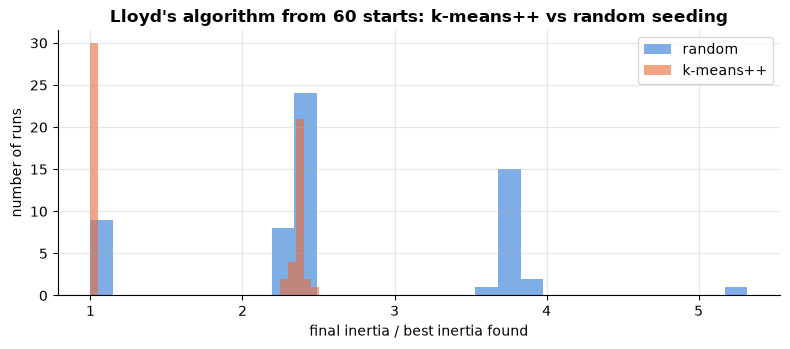

bad start with a centre at 100: 1 empty-cluster re-seed(s); final clusters [2 3 1], inertia 2.50


In [4]:
# Effect of initialisation: 10 well-separated blobs, 60 runs each of random init vs k-means++
X10, _ = make_blobs(n_samples=2000, centers=[(i * 6, j * 6) for i in range(5) for j in range(2)],
                    cluster_std=0.8, random_state=3)
res_init = {"random": [], "k-means++": []}
for s in range(60):
    for name in res_init:
        res_init[name].append(kmeans(X10, 10, init=name, seed=s)[2])
best = min(min(v) for v in res_init.values())
fig, ax = plt.subplots(figsize=(8, 3.6))
for name, col in zip(res_init, PALETTE):
    ratio = np.array(res_init[name]) / best
    ax.hist(ratio, bins=np.linspace(1, ratio.max() + 0.05, 30), alpha=0.6, label=name, color=col)
    print(f"{name:10s}: reaches the best solution in {np.mean(ratio < 1.001):.0%} of runs, median inertia/best = {np.median(ratio):.2f}")
ax.set_xlabel("final inertia / best inertia found"); ax.set_ylabel("number of runs")
ax.set_title("Lloyd's algorithm from 60 starts: k-means++ vs random seeding"); ax.legend(); plt.tight_layout(); plt.show()

# Empty clusters: a bad start where one centre is far from every point
_, lab_e, J_e, _, n_empty = kmeans(x_toy, 3, init=np.array([[1.], [11.], [100.]]))
print(f"bad start with a centre at 100: {n_empty} empty-cluster re-seed(s); final clusters {np.bincount(lab_e)}, inertia {J_e:.2f}")

**Mini-batch k-means** (Sculley, 2010) updates the centres from a small random batch each step, moving each centre towards its assigned batch points with a per-centre learning rate `1 / (number of points it has seen)`. It trades a slightly worse inertia for a large speed-up on big data.

In [5]:
def minibatch_kmeans(X, k, init, batch=1024, n_steps=60, seed=0):
    rng = np.random.default_rng(seed)
    C = init.astype(float).copy()
    counts = np.zeros(k)                                      # how many points each centre has absorbed
    for _ in range(n_steps):
        B = X[rng.integers(len(X), size=batch)]               # a random mini-batch
        lab = sq_dists(B, C).argmin(1)
        for j in range(k):
            pts = B[lab == j]
            if len(pts):
                counts[j] += len(pts)
                # per-centre learning rate 1/count: identical to feeding the points one at a time
                C[j] += (pts.sum(0) - len(pts) * C[j]) / counts[j]
    return C

Xbig, _ = make_blobs(n_samples=200000, centers=8, n_features=10, cluster_std=4.0, random_state=7)
C_start = Xbig[np.random.default_rng(4).choice(len(Xbig), 8, replace=False)]   # same random start for both
t0 = time.time(); C_full, _, J_full, it_full, _ = kmeans(Xbig, 8, init=C_start); t_full = time.time() - t0
t0 = time.time(); C_mb = minibatch_kmeans(Xbig, 8, C_start); t_mb = time.time() - t0
J_mb = sq_dists(Xbig, C_mb).min(1).sum()
print(f"full Lloyd : {t_full:.2f}s ({it_full} passes over 200,000 points = {it_full * 200000:,} point visits), inertia {J_full:,.0f}")
print(f"mini-batch : {t_mb:.2f}s (60 batches of 1024 = {60 * 1024:,} point visits), inertia {J_mb:,.0f} "
      f"({100 * (J_mb / J_full - 1):+.2f}% vs full)")

full Lloyd : 1.17s (12 passes over 200,000 points = 2,400,000 point visits), inertia 31,813,704
mini-batch : 0.05s (60 batches of 1024 = 61,440 point visits), inertia 31,967,351 (+0.48% vs full)


**What just happened?**
- Our Lloyd's algorithm reproduces the 1-D hand example and matches sklearn's `KMeans` exactly when both start from the same centres.
- With 10 blobs, **random seeding** frequently gets stuck: two centres share one blob while another centre straddles two blobs, and the final inertia is much worse. **k-means++** reaches the best solution far more often. This is why sklearn uses k-means++ and several restarts (`n_init`).
- When a centre loses all its points, we re-seed it at the point currently worst served by its centre (sklearn does something similar).
- Mini-batch k-means looks at only 61,440 points in total (less than a third of one pass over the data) and lands within a fraction of a percent of the full solution's inertia, while Lloyd needs many full passes.

**Complexity.** One Lloyd iteration is **O(N·k·d)** time and O(N + k·d) memory. k-means++ seeding is also O(N·k·d). The number of iterations is usually small in practice (tens), although the worst case is exponential. Mini-batch costs O(b·k·d) per step for batch size b.

> ⚠️ **Common mistake:** running k-means on unscaled features. Inertia uses Euclidean distance, so a feature measured in large units dominates (Section 9). K-means also assumes roughly spherical, similar-size clusters: it cannot find moons or rings (Section 5).

> 🎓 **Exam / interview tip:** "Does k-means always converge? To what?" Yes, in a finite number of steps, because the inertia strictly decreases whenever the partition changes and there are finitely many partitions; but only to a **local** minimum.

## 2. Choosing k: elbow, silhouette, gap statistic, Davies–Bouldin

> 💬 **In plain English:** several scorecards that each say how well-separated the groups are for a given number of groups.

There is no universally correct k; these **internal** criteria use only the data.

| Criterion | Definition | Pick k where… |
|---|---|---|
| **Elbow** | inertia J(k) | the curve bends (subjective) |
| **Silhouette** | per point `s = (b − a) / max(a, b)`, with a = mean distance to its own cluster, b = mean distance to the nearest other cluster; average over points | the average is highest (range −1..1) |
| **Gap statistic** (Tibshirani, Walther & Hastie, 2001) | `Gap(k) = E*[log W_k] − log W_k`, where W_k is the within-cluster sum of squares and E* averages over B reference datasets drawn uniformly in the data's bounding box | the smallest k with `Gap(k) ≥ Gap(k+1) − s_{k+1}` |
| **Davies–Bouldin** | average over clusters of `max_{j≠i} (S_i + S_j) / d(c_i, c_j)`, with S_i = mean distance of cluster i's points to its centre | the value is lowest |

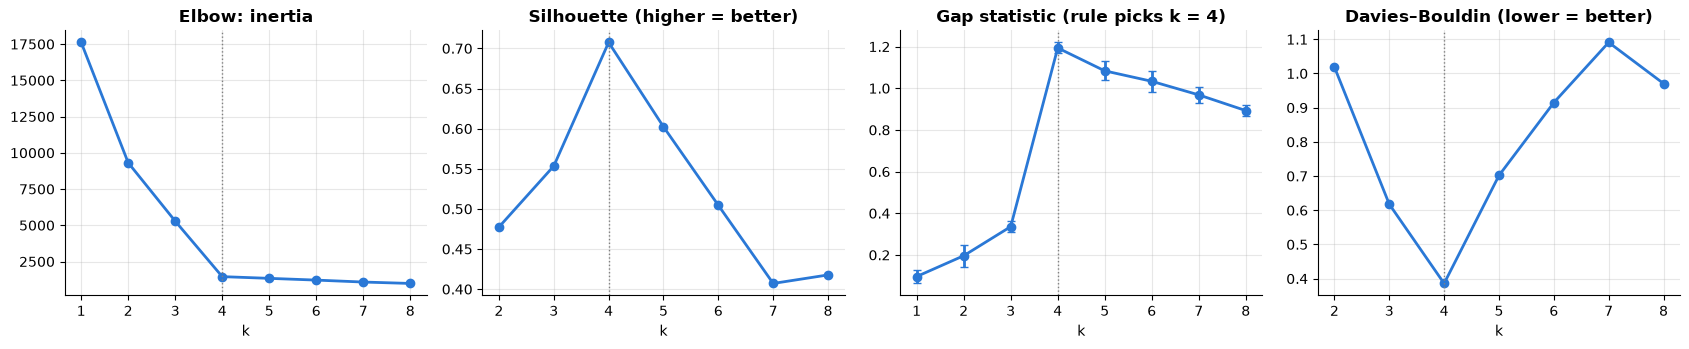

silhouette picks k = 4 | Davies-Bouldin picks k = 4 | gap statistic picks k = 4 | true k = 4


In [6]:
def silhouette(X, labels):
    D = pairwise_distances(X)
    ks = np.unique(labels)
    s = np.zeros(len(X))
    for i in range(len(X)):
        own = labels == labels[i]
        if own.sum() == 1:                                # singleton cluster: silhouette defined as 0
            continue
        a = D[i, own].sum() / (own.sum() - 1)             # exclude the point itself
        b = min(D[i, labels == k].mean() for k in ks if k != labels[i])
        s[i] = (b - a) / max(a, b)
    return s.mean()

def davies_bouldin(X, labels):
    ks = np.unique(labels)
    C = np.array([X[labels == k].mean(0) for k in ks])
    S = np.array([np.linalg.norm(X[labels == k] - C[i], axis=1).mean() for i, k in enumerate(ks)])
    M = np.linalg.norm(C[:, None] - C[None], axis=2)
    R = (S[:, None] + S[None]) / np.where(M == 0, np.inf, M)
    np.fill_diagonal(R, -np.inf)
    return R.max(1).mean()

def gap_statistic(X, k_max=8, B=10, seed=0):
    r = np.random.default_rng(seed)
    lo, hi = X.min(0), X.max(0)
    gaps, sds, logW = [], [], []
    for k in range(1, k_max + 1):
        lw = np.log(kmeans(X, k, seed=seed)[2])
        ref = [np.log(kmeans(r.uniform(lo, hi, size=X.shape), k, seed=seed)[2]) for _ in range(B)]
        gaps.append(np.mean(ref) - lw); sds.append(np.std(ref) * np.sqrt(1 + 1 / B)); logW.append(lw)
    gaps, sds = np.array(gaps), np.array(sds)
    k_hat = next(k for k in range(1, k_max) if gaps[k - 1] >= gaps[k] - sds[k])
    return gaps, sds, k_hat

X4, y4 = make_blobs(n_samples=500, centers=[(0, 0), (8, 0), (0, 8), (8, 8)], cluster_std=1.2, random_state=11)
ks = range(2, 9)
fits = {k: kmeans(X4, k, seed=0) for k in range(1, 9)}
sil = [silhouette(X4, fits[k][1]) for k in ks]
dbi = [davies_bouldin(X4, fits[k][1]) for k in ks]
for k in (3, 4, 6):                                        # verify our metrics against sklearn
    assert np.isclose(silhouette(X4, fits[k][1]), silhouette_score(X4, fits[k][1]))
    assert np.isclose(davies_bouldin(X4, fits[k][1]), davies_bouldin_score(X4, fits[k][1]))
gaps, sds, k_gap = gap_statistic(X4)

fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
ax[0].plot(range(1, 9), [fits[k][2] for k in range(1, 9)], "o-"); ax[0].set_title("Elbow: inertia")
ax[1].plot(list(ks), sil, "o-"); ax[1].set_title("Silhouette (higher = better)")
ax[2].errorbar(range(1, 9), gaps, yerr=sds, fmt="o-", capsize=3); ax[2].set_title(f"Gap statistic (rule picks k = {k_gap})")
ax[3].plot(list(ks), dbi, "o-"); ax[3].set_title("Davies–Bouldin (lower = better)")
for a in ax:
    a.axvline(4, color="grey", ls=":", lw=1); a.set_xlabel("k")
plt.tight_layout(); plt.show()
print("silhouette picks k =", list(ks)[int(np.argmax(sil))], "| Davies-Bouldin picks k =", list(ks)[int(np.argmin(dbi))],
      "| gap statistic picks k =", k_gap, "| true k = 4")

**What just happened?** All four criteria agree on the true k = 4 for these well-separated blobs (dotted line), and our silhouette and Davies–Bouldin implementations match sklearn's to floating-point precision. On real data they often disagree, which is a useful warning that the cluster structure is weak.

**Complexity.** Silhouette needs all pairwise distances: **O(N²·d)** time (sklearn offers `sample_size` for big data). Davies–Bouldin is O(N·k·d). The gap statistic runs k-means (B + 1)·k_max times.

> ⚠️ **Common mistake:** silhouette and Davies–Bouldin favour convex, well-separated blobs; they will score the "correct" moons or rings clustering **worse** than a wrong k-means split. Choose the validation criterion to match the cluster shape you expect.

## 3. Hierarchical clustering from scratch

> 💬 **In plain English:** keep joining the two closest groups and record the order, which gives a family tree of the data.

**Agglomerative clustering** starts with every point as its own cluster and repeatedly **merges the two closest clusters**, producing a tree of merges called a **dendrogram**. "Closest" depends on the **linkage**:

| Linkage | Distance between clusters A and B | Tends to give |
|---|---|---|
| **single** | min distance between a point in A and a point in B | long "chains"; finds non-convex shapes; sensitive to noise bridges |
| **complete** | max distance | compact clusters of similar diameter |
| **average** (UPGMA) | mean of all pairwise distances | a compromise |
| **Ward** | increase in total within-cluster variance caused by the merge | compact, equal-size clusters (like k-means) |

All four can be updated in O(1) per pair with the **Lance–Williams formula**: after merging i and j, the distance from any cluster k to the new cluster is
$$d(k, i\cup j) = \alpha_i d(k,i) + \alpha_j d(k,j) + \beta\, d(i,j) + \gamma\,\lvert d(k,i) - d(k,j)\rvert$$

| Linkage | αᵢ | β | γ |
|---|---|---|---|
| single | ½ | 0 | −½ |
| complete | ½ | 0 | +½ |
| average | nᵢ/(nᵢ+nⱼ) | 0 | 0 |
| Ward (on squared distances) | (nᵢ+n_k)/(nᵢ+nⱼ+n_k) | −n_k/(nᵢ+nⱼ+n_k) | 0 |

(Check single: ½a + ½b − ½|a − b| = min(a, b).)

In [7]:
def agglomerative(X, method="single"):
    """Naive O(N^3) agglomerative clustering with Lance-Williams updates.
    Returns a scipy-style linkage matrix Z: rows [cluster_a, cluster_b, height, size]."""
    N = len(X)
    D = pairwise_distances(X)
    if method == "ward":
        D = D ** 2                                           # Ward's update works on squared distances
    size = np.ones(N); ids = np.arange(N)                    # ids: scipy cluster id living in each slot
    active = np.ones(N, bool)
    off_diag = ~np.eye(N, dtype=bool)
    Z = []
    for step in range(N - 1):
        Dm = np.where(active[:, None] & active[None, :] & off_diag, D, np.inf)   # only pairs of live clusters
        i, j = np.unravel_index(Dm.argmin(), Dm.shape)       # closest pair of active clusters
        dij = D[i, j]
        ni, nj = size[i], size[j]
        nk = size
        if method == "single":
            new = 0.5 * D[i] + 0.5 * D[j] - 0.5 * np.abs(D[i] - D[j])
        elif method == "complete":
            new = 0.5 * D[i] + 0.5 * D[j] + 0.5 * np.abs(D[i] - D[j])
        elif method == "average":
            new = (ni * D[i] + nj * D[j]) / (ni + nj)
        elif method == "ward":
            new = ((ni + nk) * D[i] + (nj + nk) * D[j] - nk * dij) / (ni + nj + nk)
        Z.append([min(ids[i], ids[j]), max(ids[i], ids[j]), np.sqrt(dij) if method == "ward" else dij, ni + nj])
        D[i, :] = new; D[:, i] = new; D[i, i] = 0.0           # slot i now holds the merged cluster
        active[j] = False; size[i] = ni + nj; ids[i] = N + step
    return np.array(Z)

def cut_tree(Z, N, k):
    """Labels obtained by undoing the last k-1 merges (union-find over the first N-k merges)."""
    parent = list(range(2 * N - 1))
    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]; a = parent[a]
        return a
    for step, (a, b, _, _) in enumerate(Z[:N - k]):
        parent[find(int(a))] = N + step; parent[find(int(b))] = N + step
    roots = [find(i) for i in range(N)]
    return np.unique(roots, return_inverse=True)[1]

Xh, _ = make_blobs(n_samples=120, centers=3, cluster_std=1.0, random_state=5)
for m in ["single", "complete", "average", "ward"]:
    Z_ours = agglomerative(Xh, m)
    Z_sp = linkage(Xh, method=m)
    ok = np.allclose(np.sort(Z_ours[:, 2]), np.sort(Z_sp[:, 2]))
    print(f"{m:9s}: merge heights match scipy: {ok}")
    assert ok

single   : merge heights match scipy: True
complete : merge heights match scipy: True
average  : merge heights match scipy: True
ward     : merge heights match scipy: True


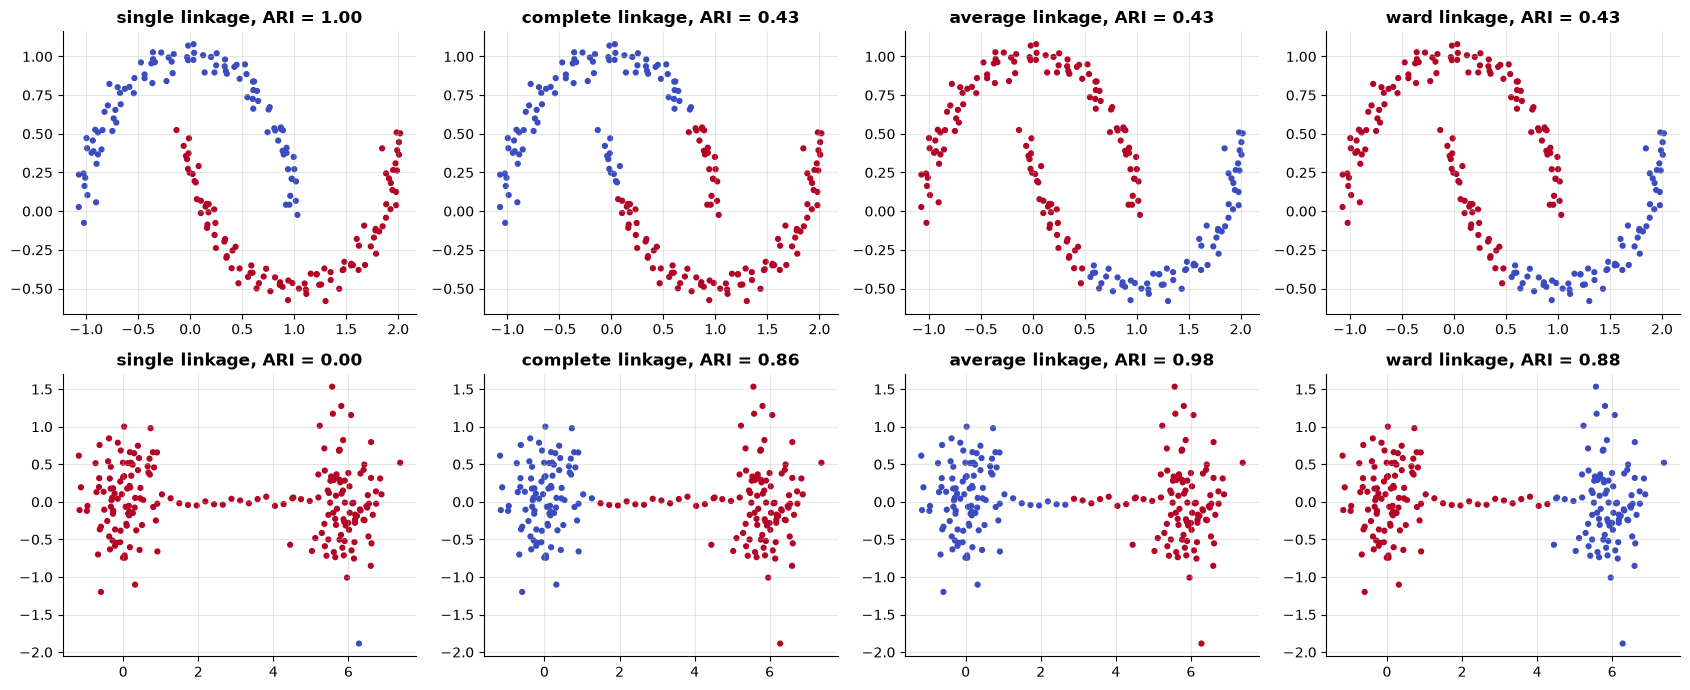

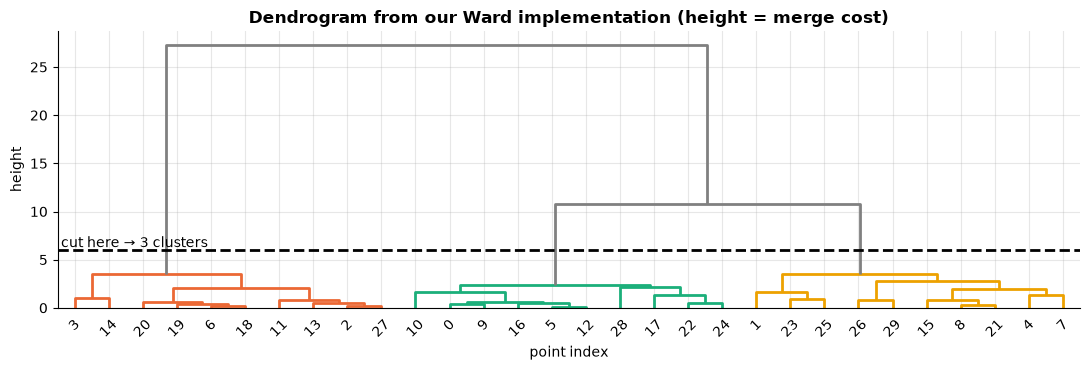

In [8]:
# Linkage behaviour on two shapes: two moons, and two blobs joined by a thin "bridge" of points
Xm, ym = make_moons(200, noise=0.05, random_state=0)
blob = np.vstack([rng.normal((0, 0), 0.5, (90, 2)), rng.normal((6, 0), 0.5, (90, 2))])
bridge = np.c_[np.linspace(0.8, 5.2, 20), rng.normal(0, 0.05, 20)]
Xbr = np.vstack([blob, bridge]); ybr = np.r_[np.zeros(90), np.ones(90), (np.linspace(0.8, 5.2, 20) > 3)].astype(int)

fig, ax = plt.subplots(2, 4, figsize=(17, 7))
for r_, (X_, y_) in enumerate([(Xm, ym), (Xbr, ybr)]):
    for c_, m in enumerate(["single", "complete", "average", "ward"]):
        lab = cut_tree(agglomerative(X_, m), len(X_), 2)
        ax[r_, c_].scatter(X_[:, 0], X_[:, 1], c=lab, cmap="coolwarm", s=12)
        ax[r_, c_].set_title(f"{m} linkage, ARI = {adjusted_rand_score(y_, lab):.2f}")
plt.tight_layout(); plt.show()

# Reading a dendrogram (Ward, 30 points from 3 blobs)
Xs, _ = make_blobs(n_samples=30, centers=3, cluster_std=0.8, random_state=2)
Zs = agglomerative(Xs, "ward")
fig, ax = plt.subplots(figsize=(11, 3.8))
dendrogram(Zs, ax=ax, color_threshold=6, above_threshold_color="grey")
ax.axhline(6, ls="--", color="k"); ax.text(1, 6.3, "cut here → 3 clusters")
ax.set_title("Dendrogram from our Ward implementation (height = merge cost)"); ax.set_xlabel("point index"); ax.set_ylabel("height")
plt.tight_layout(); plt.show()

**What just happened?** Our naive implementation reproduces scipy's merge heights for all four linkages. On the **moons**, only single linkage follows the curved shapes (it merges nearest neighbours one by one); the others cut the moons in a compact but wrong way. On the **bridged blobs**, single linkage **chains** along the bridge and keeps both blobs together as one cluster while splitting off a few stragglers, while complete, average and Ward split the two blobs. So no linkage is best everywhere.

**Reading a dendrogram:** the y-axis is the merge height. A long vertical gap before a merge means the two groups below are far apart. Cutting with a horizontal line through the largest gap gives a natural number of clusters (here 3).

**Complexity.** Our version is **O(N³)** time and O(N²) memory. Good implementations reach O(N²) time (SLINK for single linkage, the nearest-neighbour-chain algorithm for Ward/complete/average), but the O(N²) distance matrix limits plain hierarchical clustering to tens of thousands of points.

## 4. Density-based clustering: DBSCAN, OPTICS, HDBSCAN

> 💬 **In plain English:** a cluster is a crowded area; points in empty areas are called noise.

**DBSCAN** (Ester et al., 1996) defines clusters as dense regions separated by sparse ones. With radius ε and a count `min_samples`:
- a **core point** has at least `min_samples` points (itself included) within distance ε;
- a **border point** is not core but lies within ε of a core point;
- a **noise point** is neither (label −1).

A cluster is a maximal set of core points that can reach each other through chains of ε-neighbours, plus their border points. DBSCAN needs no k, finds arbitrary shapes and labels outliers, but a **single ε** cannot handle clusters of very different densities.

same core points as sklearn: True | same noise points: True | ARI vs sklearn labels: 1.0


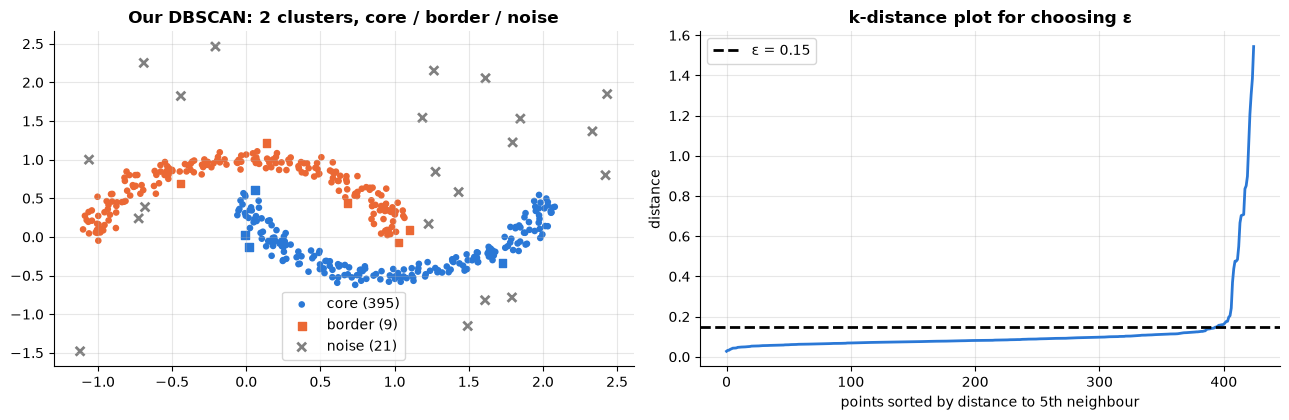

In [9]:
def dbscan(X, eps, min_samples):
    D = pairwise_distances(X)
    neighbours = [np.flatnonzero(D[i] <= eps) for i in range(len(X))]   # includes the point itself
    core = np.array([len(nb_) >= min_samples for nb_ in neighbours])
    labels = np.full(len(X), -1)
    cid = 0
    for i in range(len(X)):
        if labels[i] != -1 or not core[i]:
            continue
        labels[i] = cid
        queue = deque([i])                                   # breadth-first expansion from a core point
        while queue:
            p = queue.popleft()
            if not core[p]:
                continue                                     # border points join but do not expand
            for q in neighbours[p]:
                if labels[q] == -1:
                    labels[q] = cid
                    queue.append(q)
        cid += 1
    return labels, core

Xd, yd = make_moons(400, noise=0.07, random_state=1)
Xd = np.vstack([Xd, rng.uniform(-1.5, 2.5, (25, 2))])      # sprinkle some outliers
lab_d, core_d = dbscan(Xd, eps=0.15, min_samples=6)
skd = DBSCAN(eps=0.15, min_samples=6).fit(Xd)
sk_core = np.zeros(len(Xd), bool); sk_core[skd.core_sample_indices_] = True
print("same core points as sklearn:", np.array_equal(core_d, sk_core),
      "| same noise points:", np.array_equal(lab_d == -1, skd.labels_ == -1),
      "| ARI vs sklearn labels:", round(adjusted_rand_score(lab_d, skd.labels_), 4))
assert np.array_equal(core_d, sk_core) and np.array_equal(lab_d == -1, skd.labels_ == -1)

kinds = np.where(core_d, "core", np.where(lab_d == -1, "noise", "border"))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
for kind, mk, sz in [("core", "o", 14), ("border", "s", 30), ("noise", "x", 40)]:
    m = kinds == kind
    cols = ["grey" if l == -1 else PALETTE[l % 8] for l in lab_d[m]]
    ax[0].scatter(Xd[m, 0], Xd[m, 1], c=cols, marker=mk, s=sz, label=f"{kind} ({m.sum()})")
ax[0].legend(); ax[0].set_title(f"Our DBSCAN: {lab_d.max() + 1} clusters, core / border / noise")

# k-distance plot: a common heuristic for choosing eps (look for the knee)
kd = np.sort(NearestNeighbors(n_neighbors=6).fit(Xd).kneighbors(Xd)[0][:, -1])
ax[1].plot(kd); ax[1].axhline(0.15, ls="--", color="k", label="ε = 0.15")
ax[1].set_xlabel("points sorted by distance to 5th neighbour"); ax[1].set_ylabel("distance"); ax[1].set_title("k-distance plot for choosing ε")
ax[1].legend(); plt.tight_layout(); plt.show()

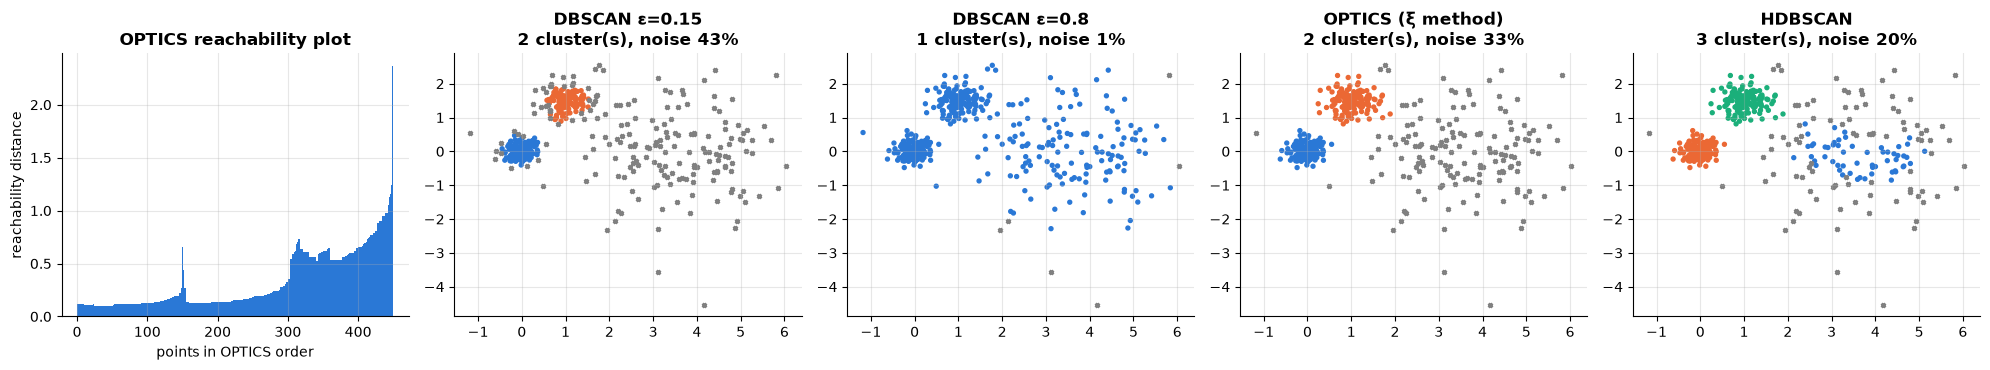

,method,clusters found,noise fraction,ARI on non-noise points
0,DBSCAN ε=0.15,2,0.43,1.00
1,DBSCAN ε=0.8,1,0.01,0.00
2,OPTICS (ξ method),2,0.33,0.98
3,HDBSCAN,3,0.20,0.98


In [10]:
# Varying density: a tight cluster, a loose cluster and a medium cluster close to the tight one
rv = np.random.default_rng(0)
Xv = np.vstack([rv.normal((0, 0), 0.2, (150, 2)), rv.normal((3.5, 0), 1.2, (150, 2)), rv.normal((1.0, 1.5), 0.3, (150, 2))])
yv = np.repeat([0, 1, 2], 150)
results = {}
for eps in (0.15, 0.8):
    results[f"DBSCAN ε={eps}"] = DBSCAN(eps=eps, min_samples=8).fit_predict(Xv)
opt = OPTICS(min_samples=20, xi=0.1).fit(Xv)
results["OPTICS (ξ method)"] = opt.labels_
results["HDBSCAN"] = HDBSCAN(min_cluster_size=20, copy=True).fit_predict(Xv)

fig, ax = plt.subplots(1, 5, figsize=(20, 3.8))
reach = opt.reachability_[opt.ordering_]
ax[0].bar(range(len(reach)), np.where(np.isinf(reach), np.nan, reach), width=1.0, color=PALETTE[0])
ax[0].set_title("OPTICS reachability plot"); ax[0].set_xlabel("points in OPTICS order"); ax[0].set_ylabel("reachability distance")
summary_rows = []
for a, (name, lab) in zip(ax[1:], results.items()):
    plot_labels(a, Xv, lab, s=8)
    kept = lab != -1
    n_cl = len(set(lab[kept]))
    a.set_title(f"{name}\n{n_cl} cluster(s), noise {np.mean(~kept):.0%}")
    summary_rows.append([name, n_cl, np.mean(~kept), adjusted_rand_score(yv[kept], lab[kept])])
plt.tight_layout(); plt.show()
pd.DataFrame(summary_rows, columns=["method", "clusters found", "noise fraction", "ARI on non-noise points"]).round(2)

**What just happened?**
- Our DBSCAN finds exactly the same core points and noise points as sklearn's, and the same clusters (ARI = 1). Core points are drawn as circles, border points as squares, noise as crosses. The **k-distance plot** (distance to the `min_samples − 1`-th neighbour, sorted) has a knee near a good ε.
- With clusters of **different densities**, no single ε works: a small ε (0.15) declares most of the loose cluster to be noise, and a large ε (0.8) merges everything into one cluster. **OPTICS** orders points so that each dense region becomes a **valley** in the reachability plot (three valleys here: a very low one for the tight cluster, a low one for the medium cluster and a high, ragged one for the loose cluster). Its automatic ξ extraction is sensitive to its settings and here returns only the two denser clusters, but the plot itself makes all three visible. **HDBSCAN** builds a hierarchy over all ε values and keeps the most persistent clusters; it recovers all three with no ε to tune, which makes it the usual default when densities vary. Both label the sparse fringe of the loose cluster as noise, which is the price of being density-based.

**Complexity.** DBSCAN with a precomputed distance matrix is **O(N²)** time and memory; with a spatial index (KD-tree, ball tree) range queries make it about O(N log N) in low dimensions, though the worst case stays O(N²). OPTICS has the same complexity; HDBSCAN is O(N²) in the worst case and much faster in practice with tree-based minimum spanning trees.

## 5. Spectral clustering from scratch

> 💬 **In plain English:** connect each point to its neighbours and cut the resulting network where it has the fewest links.

**Intuition.** Turn the data into a **graph**: connect each point to its near neighbours. Clusters become groups of nodes with many edges inside and few edges between them. Finding such groups is a graph-cut problem, and its relaxed version is solved by **eigenvectors of the graph Laplacian** (see [graph theory](../../14_Mathematics/discrete_math/03_graph_theory.ipynb)). In the eigenvector coordinates the clusters become compact blobs that even k-means can separate.

**Algorithm (Ng, Jordan & Weiss, 2001):**
1. Build a symmetric affinity matrix W (here: a k-nearest-neighbour graph).
2. Degree matrix D = diag(Σⱼ Wᵢⱼ); normalised Laplacian `L_sym = I − D^{−1/2} W D^{−1/2}`.
3. Take the eigenvectors of the k **smallest** eigenvalues of L_sym, as columns of U (N × k).
4. Normalise each row of U to unit length.
5. Run k-means on the rows of U.

**Key fact:** the multiplicity of eigenvalue 0 of a graph Laplacian equals the **number of connected components**. If clusters were perfectly disconnected, the bottom eigenvectors would be exact cluster indicators.

circles: k-means ARI -0.00, our spectral ARI 1.00, sklearn spectral ARI 1.00; eigenvalues ≈ 0: 2
moons: k-means ARI 0.27, our spectral ARI 1.00, sklearn spectral ARI 1.00; eigenvalues ≈ 0: 2


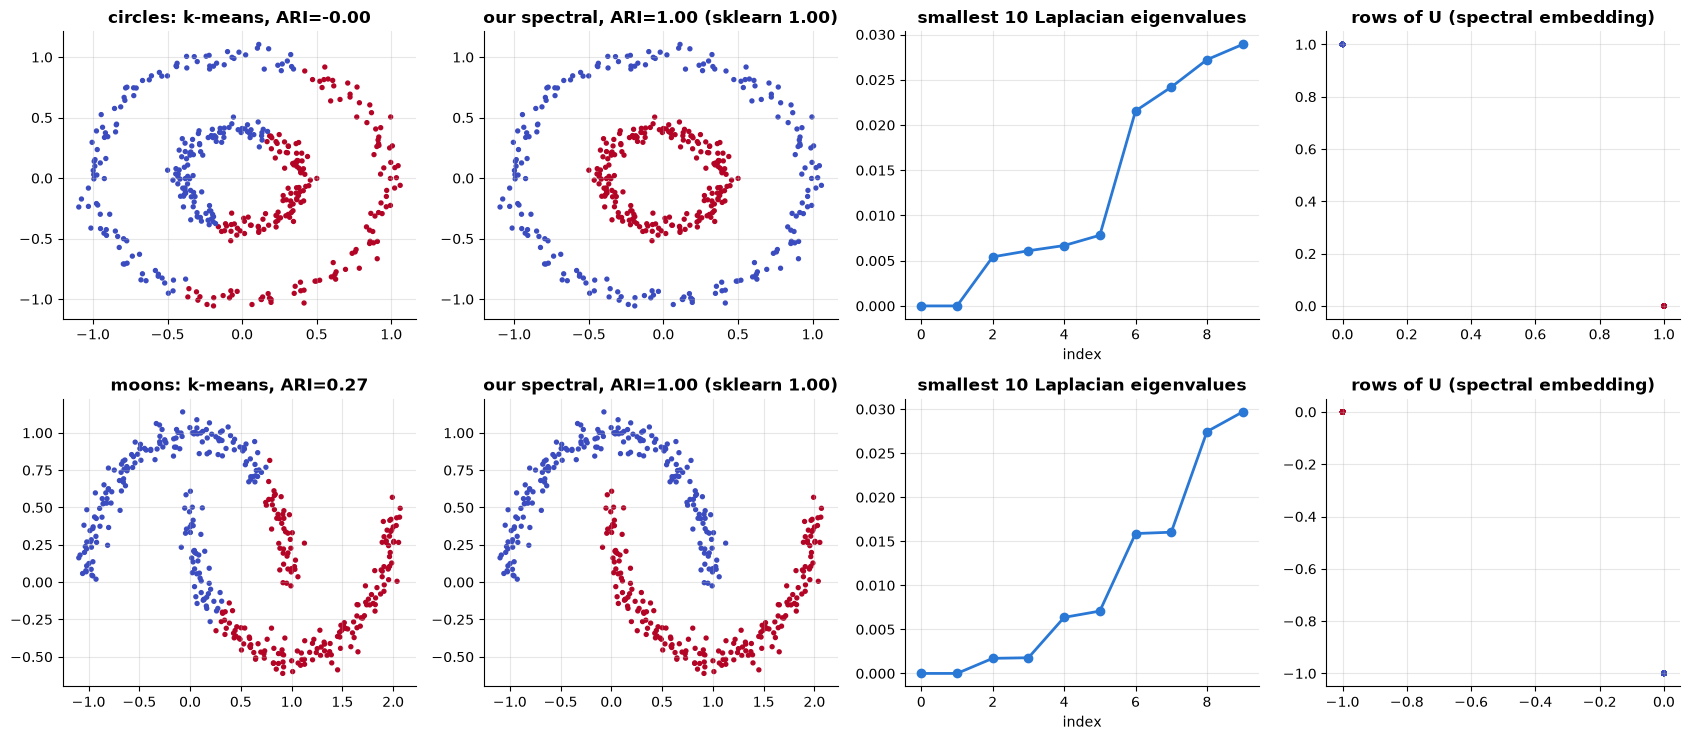

In [11]:
def spectral_clustering(X, k, n_neighbors=10, seed=0):
    A = kneighbors_graph(X, n_neighbors, include_self=False).toarray()
    W = np.maximum(A, A.T)                                  # symmetrise: i~j if either is a neighbour of the other
    d = W.sum(1)
    Dm12 = 1 / np.sqrt(d)
    L = np.eye(len(X)) - Dm12[:, None] * W * Dm12[None, :]  # normalised Laplacian
    vals, vecs = np.linalg.eigh(L)                          # ascending eigenvalues
    U = vecs[:, :k]
    U = U / np.linalg.norm(U, axis=1, keepdims=True)        # row normalisation
    best = min((kmeans(U, k, seed=s) for s in range(5)), key=lambda r: r[2])
    return best[1], vals, U

Xc, yc = make_circles(400, factor=0.4, noise=0.05, random_state=0)
Xm2, ym2 = make_moons(400, noise=0.06, random_state=0)
fig, ax = plt.subplots(2, 4, figsize=(17, 7.5))
for r_, (X_, y_, name) in enumerate([(Xc, yc, "circles"), (Xm2, ym2, "moons")]):
    lab_sp, vals, U = spectral_clustering(X_, 2)
    lab_km = kmeans(X_, 2, seed=0)[1]
    with warnings.catch_warnings():                          # sklearn warns that the kNN graph has 2 components:
        warnings.simplefilter("ignore", UserWarning)         # that is exactly the point of this demo
        lab_sk = SpectralClustering(2, affinity="nearest_neighbors", n_neighbors=10, random_state=0).fit_predict(X_)
    ax[r_, 0].scatter(*X_.T, c=lab_km, cmap="coolwarm", s=8); ax[r_, 0].set_title(f"{name}: k-means, ARI={adjusted_rand_score(y_, lab_km):.2f}")
    ax[r_, 1].scatter(*X_.T, c=lab_sp, cmap="coolwarm", s=8)
    ax[r_, 1].set_title(f"our spectral, ARI={adjusted_rand_score(y_, lab_sp):.2f} (sklearn {adjusted_rand_score(y_, lab_sk):.2f})")
    ax[r_, 2].plot(vals[:10], "o-"); ax[r_, 2].set_title("smallest 10 Laplacian eigenvalues"); ax[r_, 2].set_xlabel("index")
    ax[r_, 3].scatter(U[:, 0], U[:, 1], c=y_, cmap="coolwarm", s=8); ax[r_, 3].set_title("rows of U (spectral embedding)")
    print(f"{name}: k-means ARI {adjusted_rand_score(y_, lab_km):.2f}, our spectral ARI {adjusted_rand_score(y_, lab_sp):.2f}, "
          f"sklearn spectral ARI {adjusted_rand_score(y_, lab_sk):.2f}; eigenvalues ≈ 0: {(vals < 1e-8).sum()}")
plt.tight_layout(); plt.show()

**What just happened?** K-means splits rings and moons with a straight line (low ARI). Spectral clustering on a 10-nearest-neighbour graph separates them perfectly, matching sklearn's `SpectralClustering`. The eigenvalue plot shows **two eigenvalues at (numerically) zero**: the kNN graph has two connected components, one per ring or moon, so the first two eigenvectors are cluster indicators and the spectral embedding collapses each cluster to a tight point.

**Complexity.** A dense eigendecomposition is **O(N³)** time and O(N²) memory; with a sparse kNN graph and an iterative eigensolver (Lanczos/LOBPCG) that needs only k eigenvectors, the cost drops to roughly O(N·k·iterations), which is how sklearn scales it.

> ⚠️ **Common mistake:** choosing the graph badly. Too few neighbours fragments a cluster into several components; too many (or an RBF bandwidth that is too wide) connects different clusters. The eigenvalue gap is the diagnostic: a big jump after the k-th eigenvalue suggests k clusters.

## 6. External metrics and stability

> 💬 **In plain English:** when you do have true labels, measure agreement fairly; and check that the clusters come back when the data are resampled.

When ground-truth labels exist (benchmarks, or a small labelled audit set), compare the clustering to them with **external** metrics. All are computed from the **contingency table** n_ij = number of points in true class i and cluster j.

| Metric | Formula | Notes |
|---|---|---|
| **Purity** | `(1/N) Σ_j max_i n_ij` | easy to explain; but N singleton clusters give purity 1 |
| **NMI** | `I(U;V) / ((H(U) + H(V)) / 2)` | 0..1; label-permutation invariant; slightly positive for random labels with many clusters |
| **ARI** (Hubert & Arabie) | `(Index − Expected) / (Max − Expected)` with Index = Σ C(n_ij, 2) | 1 = identical, about 0 for random labels, can be negative |

**Stability.** If a clustering reflects real structure, it should come back when the data are perturbed. Draw two bootstrap samples, cluster both, label all original points with each solution (nearest centre), and compute the ARI between the two labellings. Repeat and average (Ben-Hur, Elisseeff & Guyon, 2002).

In [12]:
from math import comb

def contingency(a, b):
    ua, ia = np.unique(a, return_inverse=True); ub, ib = np.unique(b, return_inverse=True)
    M = np.zeros((len(ua), len(ub)), int)
    np.add.at(M, (ia, ib), 1)
    return M

def purity(y, lab):
    return contingency(y, lab).max(0).sum() / len(y)

def nmi(y, lab):
    M = contingency(y, lab) / len(y)
    pu, pv = M.sum(1), M.sum(0)
    nz = M > 0
    I = (M[nz] * np.log(M[nz] / np.outer(pu, pv)[nz])).sum()
    H = lambda p: -(p[p > 0] * np.log(p[p > 0])).sum()
    return I / ((H(pu) + H(pv)) / 2) if H(pu) + H(pv) > 0 else 1.0

def ari(y, lab):
    M = contingency(y, lab)
    idx = sum(comb(int(v), 2) for v in M.ravel())
    a = sum(comb(int(v), 2) for v in M.sum(1)); b = sum(comb(int(v), 2) for v in M.sum(0))
    exp_ = a * b / comb(len(y), 2)
    return (idx - exp_) / (0.5 * (a + b) - exp_)

r6 = np.random.default_rng(6)
for _ in range(5):                                          # check against sklearn on random labellings
    y_ = r6.integers(0, 4, 300); l_ = np.where(r6.random(300) < 0.6, y_, r6.integers(0, 5, 300))
    assert np.isclose(ari(y_, l_), adjusted_rand_score(y_, l_)) and np.isclose(nmi(y_, l_), normalized_mutual_info_score(y_, l_))
print("our ARI and NMI match sklearn on 5 random cases")

y_true = np.repeat(np.arange(4), 100)
rows = []
for name, lab in [("perfect (relabelled)", (y_true + 1) % 4), ("random, 4 clusters", r6.integers(0, 4, 400)),
                  ("random, 50 clusters", r6.integers(0, 50, 400)), ("every point alone", np.arange(400))]:
    rows.append([name, purity(y_true, lab), nmi(y_true, lab), ari(y_true, lab)])
pd.DataFrame(rows, columns=["clustering", "purity", "NMI", "ARI"]).round(3)

our ARI and NMI match sklearn on 5 random cases


,clustering,purity,NMI,ARI
0,perfect (relabelled),1.000,1.000,1.000
1,"random, 4 clusters",0.295,0.007,-0.001
2,"random, 50 clusters",0.430,0.078,-0.001
3,every point alone,1.000,0.376,0.000


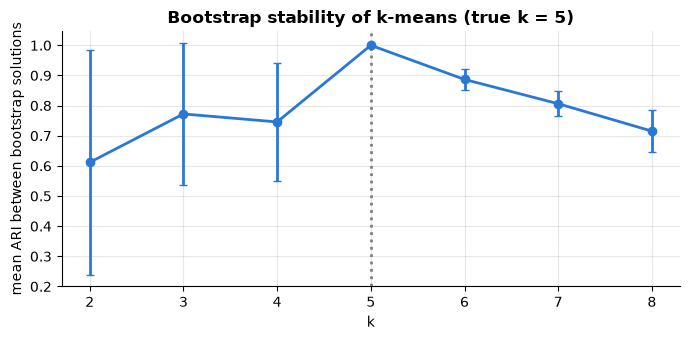

{2: np.float64(0.612), 3: np.float64(0.772), 4: np.float64(0.746), 5: np.float64(1.0), 6: np.float64(0.887), 7: np.float64(0.806), 8: np.float64(0.715)}


In [13]:
def stability(X, k, n_pairs=15, seed=0):
    r = np.random.default_rng(seed)
    scores = []
    for _ in range(n_pairs):
        labs = []
        for _ in range(2):
            idx = r.integers(0, len(X), len(X))             # bootstrap sample
            C = KMeans(k, n_init=3, random_state=int(r.integers(1e6))).fit(X[idx]).cluster_centers_
            labs.append(sq_dists(X, C).argmin(1))            # label ALL original points
        scores.append(adjusted_rand_score(*labs))
    return np.mean(scores), np.std(scores)

ang5 = np.linspace(0, 2 * np.pi, 6)[:5]                          # 5 blobs on a pentagon
X5, y5 = make_blobs(n_samples=600, centers=np.c_[7 * np.cos(ang5), 7 * np.sin(ang5)], cluster_std=1.3, random_state=21)
stab = {k: stability(X5, k) for k in range(2, 9)}
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.errorbar(list(stab), [m for m, s in stab.values()], yerr=[s for m, s in stab.values()], fmt="o-", capsize=3)
ax.axvline(5, ls=":", color="grey"); ax.set_xlabel("k"); ax.set_ylabel("mean ARI between bootstrap solutions")
ax.set_title("Bootstrap stability of k-means (true k = 5)"); plt.tight_layout(); plt.show()
print({k: round(m, 3) for k, (m, s) in stab.items()})

**What just happened?** Our ARI and NMI agree with sklearn's. The table shows why ARI is usually preferred: purity rewards putting every point alone (purity 1.0); NMI rises to 0.08 for 50 random clusters and to 0.38 when every point is alone, although neither clustering carries any information; ARI stays at about 0 for every uninformative clustering and is 1 only for the perfect one (whatever the label names). Adjusted mutual information (AMI) corrects NMI for chance in the same way.

In the stability curve, k-means solutions at the true k = 5 are reproduced perfectly across bootstrap samples (mean ARI 1.0). With k < 5, k-means must merge neighbouring blobs, and on a symmetric pentagon there are several equally good ways to do so; with k > 5 it must split a real blob somewhere arbitrary. Either way the bootstrap solutions disagree, so stability drops.

> ⚠️ **Common mistake:** treating stability as proof. A wrong k can also be stable when there is one obviously best way to merge (for example two pairs of nearby blobs at k = 2), so use stability together with internal criteria and domain knowledge.

## 7. Manifold learning: ICA, MDS, Isomap, LLE and t-SNE pitfalls

> 💬 **In plain English:** draw a 2-D map of high-dimensional data, either by unmixing signals or by keeping neighbours together.

### 7.1 ICA: the cocktail-party problem
**Intuition.** Three people talk at once and three microphones each record a different mixture. **Independent Component Analysis** recovers the original voices, assuming they are **statistically independent and non-Gaussian**. PCA only makes signals *uncorrelated*, which is weaker; ICA pushes further by making them as **non-Gaussian** as possible (by the central limit theorem, mixtures are more Gaussian than their sources).

**Model:** x = A s, with an unknown mixing matrix A. We want W ≈ A⁻¹ so that s = W x. Sources can only be recovered up to **order, sign and scale**.

**FastICA (Hyvärinen, 1999), symmetric version with g = tanh:**
1. Centre and **whiten** x (so that Cov = I).
2. Repeat: `W ← E[g(Wx) xᵀ] − diag(E[g′(Wx)]) W`, then **decorrelate** `W ← (W Wᵀ)^{−1/2} W`, until W stops changing.

our FastICA converged in 6 iterations
          our FastICA  sklearn FastICA    PCA
sine            0.998            0.998  0.739
square          1.000            1.000  0.771
sawtooth        0.999            0.999  0.658


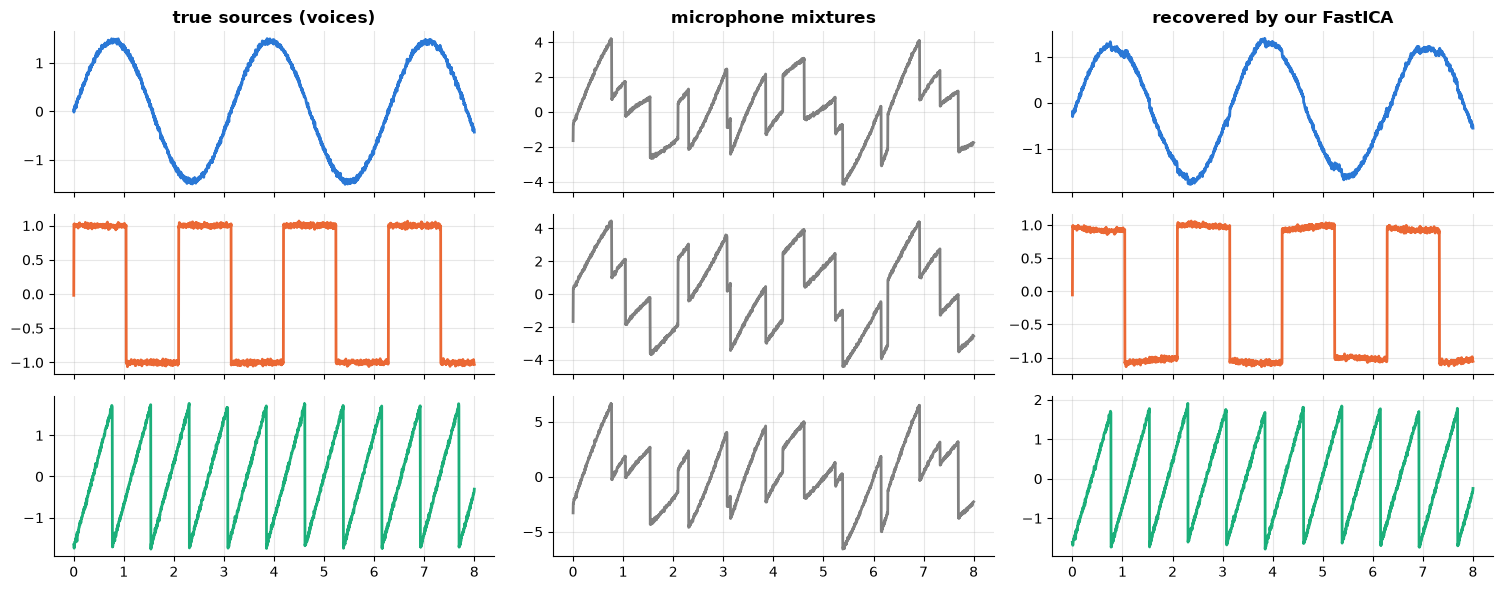

In [14]:
t_ = np.linspace(0, 8, 2000)
S_true = np.c_[np.sin(2 * t_), np.sign(np.sin(3 * t_)), 2 * ((t_ * 1.3) % 1) - 1]   # sine, square, sawtooth
S_true += 0.02 * rng.normal(size=S_true.shape)
S_true /= S_true.std(0)
A_mix = np.array([[1.0, 1.0, 1.0], [0.5, 2.0, 1.0], [1.5, 1.0, 2.0]])
Xmix = S_true @ A_mix.T                                       # what the microphones record

def fastica(X, n_iter=500, tol=1e-8, seed=0):
    Xc = X - X.mean(0)
    vals, E = np.linalg.eigh(np.cov(Xc.T))
    K = E @ np.diag(vals ** -0.5) @ E.T                        # whitening matrix
    Z = Xc @ K.T                                               # whitened data: Cov(Z) = I
    W = np.random.default_rng(seed).normal(size=(X.shape[1],) * 2)
    def sym_decorrelate(W):
        s, U = np.linalg.eigh(W @ W.T)
        return U @ np.diag(s ** -0.5) @ U.T @ W                # (W W^T)^(-1/2) W
    W = sym_decorrelate(W)
    for it in range(n_iter):
        WZ = Z @ W.T                                           # current source estimates, (N, k)
        g, g_prime = np.tanh(WZ), 1 - np.tanh(WZ) ** 2
        W_new = sym_decorrelate(g.T @ Z / len(Z) - np.diag(g_prime.mean(0)) @ W)
        converged = np.max(np.abs(np.abs(np.diag(W_new @ W.T)) - 1)) < tol
        W = W_new
        if converged:
            break
    return Z @ W.T, it + 1

def match_abs_corr(S_est, S_ref):
    """Best |correlation| of each true source with any estimated component."""
    C = np.abs(np.corrcoef(S_ref.T, S_est.T)[:3, 3:])
    return C.max(1)

S_ica, n_it = fastica(Xmix)
S_sk = FastICA(3, whiten="unit-variance", random_state=0).fit_transform(Xmix)
S_pca = PCA(3).fit_transform(Xmix)
print(f"our FastICA converged in {n_it} iterations")
print(pd.DataFrame({"our FastICA": match_abs_corr(S_ica, S_true), "sklearn FastICA": match_abs_corr(S_sk, S_true),
                    "PCA": match_abs_corr(S_pca, S_true)}, index=["sine", "square", "sawtooth"]).round(3))

fig, ax = plt.subplots(3, 3, figsize=(15, 6), sharex=True)
for j in range(3):
    ax[j, 0].plot(t_, S_true[:, j], color=PALETTE[j]); ax[j, 1].plot(t_, Xmix[:, j], color="grey")
    k_best = np.argmax(np.abs(np.corrcoef(S_true[:, j], S_ica.T)[0, 1:]))
    ax[j, 2].plot(t_, S_ica[:, k_best] * np.sign(np.corrcoef(S_true[:, j], S_ica[:, k_best])[0, 1]), color=PALETTE[j])
ax[0, 0].set_title("true sources (voices)"); ax[0, 1].set_title("microphone mixtures"); ax[0, 2].set_title("recovered by our FastICA")
plt.tight_layout(); plt.show()

**What just happened?** From three mixed recordings, our FastICA recovered all three sources with |correlation| ≈ 1.0 (after fixing sign and order, which ICA cannot know), just like sklearn's. PCA only decorrelates, so its components are still mixtures of the sources and correlate less with each of them.

### 7.2 MDS, Isomap and LLE on the swiss roll
**Classical (Torgerson) MDS:** given a distance matrix D, double-centre the squared distances, `B = −½ J D⁽²⁾ J` with `J = I − (1/N)11ᵀ`, and take the top eigenvectors scaled by √eigenvalue. With Euclidean distances this is exactly **PCA**: a linear projection, which cannot unroll a curled sheet.

**Isomap** (Tenenbaum, de Silva & Langford, 2000) replaces Euclidean distances with **geodesic** distances: build a kNN graph and compute shortest paths along it (Dijkstra), then run classical MDS. Distances are measured *along* the sheet.

**LLE** (Roweis & Saul, 2000): write each point as a weighted average of its neighbours (`min ‖xᵢ − Σⱼ wᵢⱼ xⱼ‖²`, Σⱼ wᵢⱼ = 1), then find low-dimensional points that keep the **same weights**: the bottom eigenvectors of `M = (I − W)ᵀ(I − W)`, skipping the constant one.

embeddings computed in 2.7s
classical MDS (= PCA)    0.198
our Isomap               1.000
our LLE                  1.000
sklearn Isomap           1.000
sklearn LLE              1.000
Name: |Spearman ρ| with roll position, dtype: float64


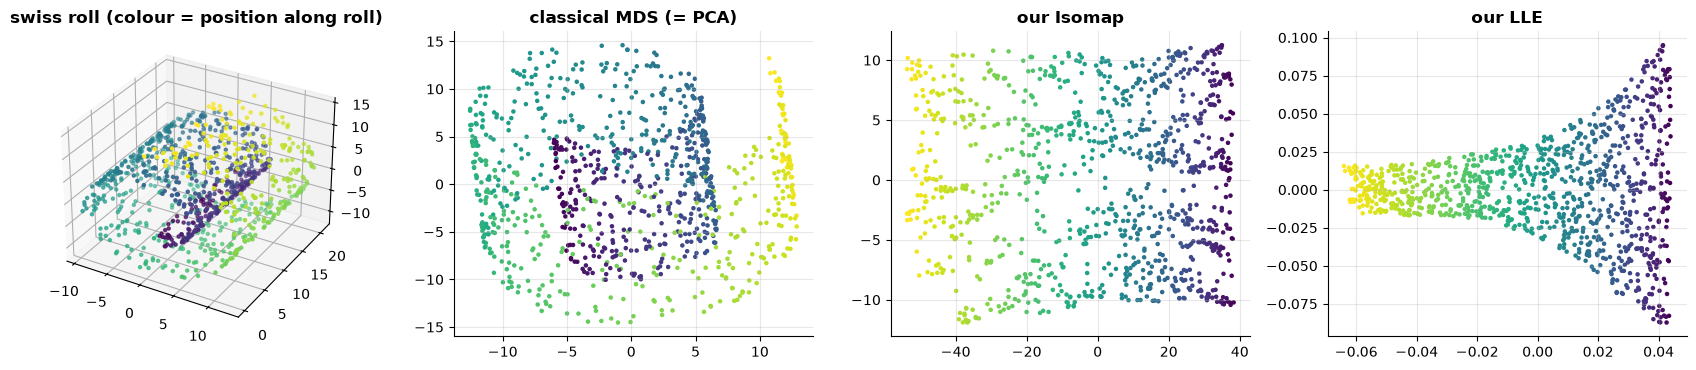

In [15]:
Xsr, t_sr = make_swiss_roll(1000, noise=0.05, random_state=0)   # t_sr = position along the roll

def classical_mds(D, dim=2):
    N = len(D)
    J = np.eye(N) - np.ones((N, N)) / N
    B = -0.5 * J @ (D ** 2) @ J                                  # double centring
    vals, vecs = np.linalg.eigh(B)
    idx = np.argsort(vals)[::-1][:dim]
    return vecs[:, idx] * np.sqrt(np.maximum(vals[idx], 0))

def isomap(X, n_neighbors=10, dim=2):
    G = kneighbors_graph(X, n_neighbors, mode="distance")        # sparse weighted kNN graph
    Dg = shortest_path(G, method="D", directed=False)            # geodesic distances (Dijkstra)
    assert np.isfinite(Dg).all(), "kNN graph is disconnected: increase n_neighbors"
    return classical_mds(Dg, dim)

def lle(X, n_neighbors=12, dim=2, reg=1e-3):
    N = len(X)
    nbrs = NearestNeighbors(n_neighbors=n_neighbors + 1).fit(X).kneighbors(X)[1][:, 1:]   # drop self
    W = np.zeros((N, N))
    for i in range(N):
        Zi = X[nbrs[i]] - X[i]                                   # neighbours relative to x_i
        C = Zi @ Zi.T
        C += reg * np.trace(C) * np.eye(n_neighbors)             # regularise (C is singular when k > d)
        w = np.linalg.solve(C, np.ones(n_neighbors))
        W[i, nbrs[i]] = w / w.sum()                              # weights sum to 1
    M = (np.eye(N) - W).T @ (np.eye(N) - W)
    vals, vecs = np.linalg.eigh(M)
    return vecs[:, 1:dim + 1]                                    # skip the constant eigenvector

t0 = time.time()
emb = {"classical MDS (= PCA)": classical_mds(pairwise_distances(Xsr)),
       "our Isomap": isomap(Xsr), "our LLE": lle(Xsr)}
emb_sk = {"sklearn Isomap": Isomap(n_neighbors=10, n_components=2).fit_transform(Xsr),
          "sklearn LLE": LocallyLinearEmbedding(n_neighbors=12, n_components=2, random_state=0).fit_transform(Xsr)}
print(f"embeddings computed in {time.time() - t0:.1f}s")
def unroll_score(E):
    """How well does some 1-D direction of the embedding recover the roll position t? (|Spearman| of best axis)"""
    return max(abs(spearmanr(E[:, j], t_sr)[0]) for j in range(E.shape[1]))
print(pd.Series({k: unroll_score(v) for k, v in {**emb, **emb_sk}.items()}, name="|Spearman ρ| with roll position").round(3))

fig = plt.figure(figsize=(17, 3.8))
a3 = fig.add_subplot(1, 4, 1, projection="3d")
a3.scatter(*Xsr.T, c=t_sr, cmap="viridis", s=5); a3.set_title("swiss roll (colour = position along roll)")
for i, (name, E) in enumerate(emb.items()):
    a = fig.add_subplot(1, 4, i + 2)
    a.scatter(E[:, 0], E[:, 1], c=t_sr, cmap="viridis", s=5); a.set_title(name)
plt.tight_layout(); plt.show()

**What just happened?** Classical MDS on straight-line distances is just PCA: it squashes the roll and mixes colours from different layers. **Isomap** unrolls it into a rectangle with a smooth colour gradient, because it measures distance along the kNN graph. **LLE** also recovers the roll order, though its embedding is typically more distorted. The Spearman correlation between the best embedding axis and the true roll position quantifies this, and our implementations score like sklearn's.

**Complexity.** kNN graph O(N² d) naively (or about O(N log N) with trees); Isomap's all-pairs shortest paths O(N² log N + N·E) with Dijkstra plus an O(N³) dense eigendecomposition; LLE needs O(N k³) for the weights and an eigenproblem on a sparse N × N matrix.

### 7.3 t-SNE pitfalls: what perplexity does
**t-SNE** (van der Maaten & Hinton, 2008) keeps **neighbourhoods**, not distances. Its main knob, **perplexity**, is roughly the number of neighbours each point "pays attention to". Three facts that are easy to forget:
1. **Cluster sizes** in a t-SNE plot mean nothing (dense and spread-out clusters come out the same size).
2. **Distances between clusters** mean little.
3. A low perplexity can make **random noise** look clustered.

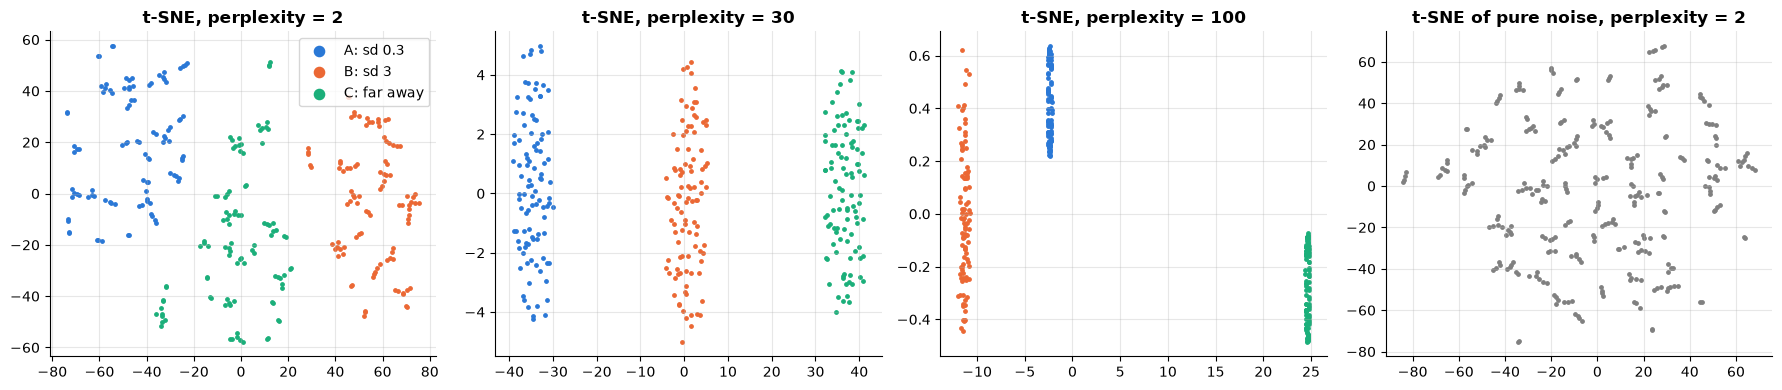

4 t-SNE runs in 8.7s
true spread (mean distance to centre) A, B: [0.87, 9.47]
umap-learn is not installed: skipping the optional UMAP comparison (pip install umap-learn).


In [16]:
# Three 10-D Gaussian clusters: A tight (sd 0.3), B wide (sd 3), C far away from both
r7 = np.random.default_rng(7)
Xt = np.vstack([r7.normal(0, 0.3, (100, 10)), r7.normal(0, 3.0, (100, 10)) + 8, r7.normal(0, 1.0, (100, 10)) + 40])
yt_ = np.repeat([0, 1, 2], 100)
noise = r7.normal(size=(300, 10))                                  # pure noise, no clusters at all
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
t0 = time.time()
for a, perp in zip(ax[:3], [2, 30, 100]):
    E = TSNE(perplexity=perp, init="pca", random_state=0).fit_transform(Xt)
    for c, name in zip(range(3), ["A: sd 0.3", "B: sd 3", "C: far away"]):
        a.scatter(*E[yt_ == c].T, s=6, label=name)
    a.set_title(f"t-SNE, perplexity = {perp}")
ax[0].legend(markerscale=3)
E = TSNE(perplexity=2, init="pca", random_state=0).fit_transform(noise)
ax[3].scatter(*E.T, s=6, color="grey"); ax[3].set_title("t-SNE of pure noise, perplexity = 2")
plt.tight_layout(); plt.show()
print(f"4 t-SNE runs in {time.time() - t0:.1f}s")
print("true spread (mean distance to centre) A, B:",
      [round(float(np.linalg.norm(Xt[yt_ == c] - Xt[yt_ == c].mean(0), axis=1).mean()), 2) for c in (0, 1)])

try:                                                               # optional dependency
    import umap
    Eu = umap.UMAP(random_state=0).fit_transform(Xt)
    print("UMAP embedding computed:", Eu.shape)
except ImportError:
    print("umap-learn is not installed: skipping the optional UMAP comparison (pip install umap-learn).")

**What just happened?** Cluster B is ten times more spread out than A in the original space, yet at perplexity 30 and 100 the two blobs come out with similar on-screen sizes, and the gap to the far-away cluster C is not drawn to scale. At perplexity 2, real clusters fracture into little islands, and even **pure noise** shows clumps that look like structure. Rules: try several perplexities (5–50 is typical, and it must be below the number of points), never read sizes or inter-cluster distances, and confirm any "cluster" with another method.

> 🎓 **Exam / interview tip:** "PCA vs t-SNE vs UMAP?" PCA is linear, fast, deterministic, preserves global variance and can transform new points. t-SNE preserves local neighbourhoods, is for **visualisation only**, has no natural transform for new points. UMAP is similar in spirit to t-SNE, faster, keeps a bit more global structure, and does support transforming new points.

## 8. NMF: parts-based representations

> 💬 **In plain English:** describe each image as a sum of non-negative parts, like strokes adding up to a digit.

**Non-negative matrix factorisation** approximates a non-negative data matrix V (N × d) as `V ≈ W H` with W (N × r) ≥ 0 and H (r × d) ≥ 0. Because nothing can be subtracted, each item is built by **adding parts**, which gives interpretable components: strokes of digits, topics in documents, ingredients of a spectrum. PCA components, in contrast, mix positive and negative values and look "holistic".

**Lee & Seung (2001) multiplicative updates** for `min ‖V − WH‖²_F`:
$$H \leftarrow H \odot \frac{W^\top V}{W^\top W H}, \qquad W \leftarrow W \odot \frac{V H^\top}{W H H^\top}$$
They keep everything non-negative automatically and never increase the error.

NMF in 1.1s | Frobenius error: ours 709.1, sklearn NMF 696.6, PCA (16 comps, unconstrained) 570.2
fraction of exactly-zero / near-zero (<1e-3) entries in H: ours 66%; PCA components negative entries: 44%


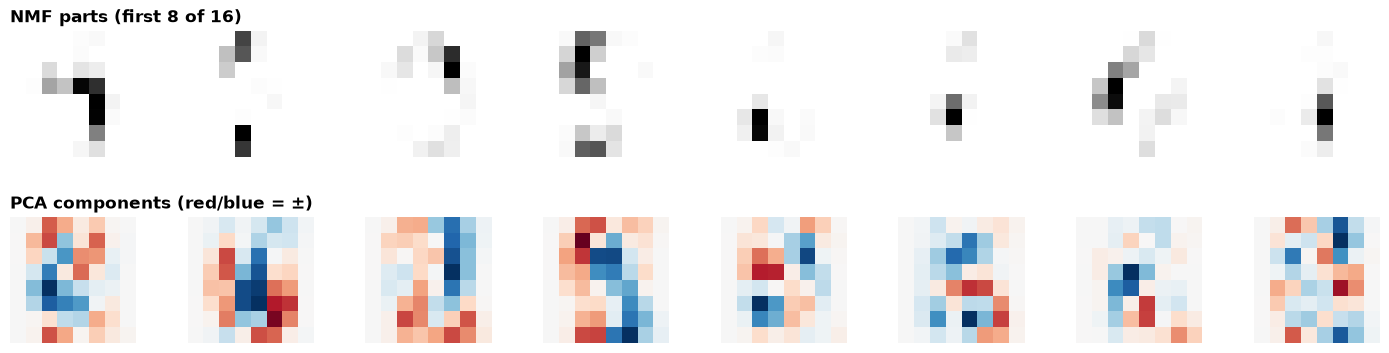

In [17]:
digits = load_digits()
V = digits.data                                                # 1797 x 64, pixel values 0..16 (non-negative)

def nmf_mu(V, r, n_iter=400, seed=0, eps=1e-10):
    rng_ = np.random.default_rng(seed)
    scale = np.sqrt(V.mean() / r)
    W = rng_.random((V.shape[0], r)) * scale; H = rng_.random((r, V.shape[1])) * scale
    errs = []
    for _ in range(n_iter):
        H *= (W.T @ V) / (W.T @ W @ H + eps)
        W *= (V @ H.T) / (W @ H @ H.T + eps)
        errs.append(np.linalg.norm(V - W @ H))
    return W, H, np.array(errs)

t0 = time.time()
W_n, H_n, errs = nmf_mu(V, 16)
assert np.all(np.diff(errs) <= 1e-6 * errs[:-1]), "multiplicative updates must not increase the error"
sk_nmf = NMF(16, init="random", solver="mu", max_iter=400, random_state=0, tol=0)
W_sk = sk_nmf.fit_transform(V)
pca16 = PCA(16).fit(V)
err_pca = np.linalg.norm(V - pca16.inverse_transform(pca16.transform(V)))
print(f"NMF in {time.time() - t0:.1f}s | Frobenius error: ours {errs[-1]:.1f}, sklearn NMF {sk_nmf.reconstruction_err_:.1f}, "
      f"PCA (16 comps, unconstrained) {err_pca:.1f}")
print(f"fraction of exactly-zero / near-zero (<1e-3) entries in H: ours {np.mean(H_n < 1e-3):.0%}; "
      f"PCA components negative entries: {np.mean(pca16.components_ < 0):.0%}")

fig, ax = plt.subplots(2, 8, figsize=(14, 4))
for i in range(8):
    ax[0, i].imshow(H_n[i].reshape(8, 8), cmap="Greys"); ax[0, i].axis("off")
    m_ = np.abs(pca16.components_[i]).max()
    ax[1, i].imshow(pca16.components_[i].reshape(8, 8), cmap="RdBu", vmin=-m_, vmax=m_); ax[1, i].axis("off")
ax[0, 0].set_title("NMF parts (first 8 of 16)", loc="left"); ax[1, 0].set_title("PCA components (red/blue = ±)", loc="left")
plt.tight_layout(); plt.show()

**What just happened?** Our multiplicative-update NMF never increased the error (asserted), and reaches about the same reconstruction error as sklearn's NMF with the same solver. PCA reconstructs slightly better (it is the optimal rank-16 approximation without constraints), but its components are signed, global patterns, while the NMF components are **localised strokes** (parts of loops and bars) that add up to digits, and many entries of H are close to zero (a sparse, parts-based code).

**Complexity.** Each multiplicative-update iteration costs **O(N·d·r)**. NMF is non-convex, so results depend on initialisation (sklearn's `nndsvda` init is a good default).

## 9. A practical recipe: scaling, distances and high dimensions

> 💬 **In plain English:** put features on the same scale and be suspicious of distances in very many dimensions.

Distance-based methods (k-means, hierarchical, DBSCAN, spectral, t-SNE, kNN) are only as good as the distance you give them.

k-means ARI on raw features: -0.00 | after standardising: 1.00


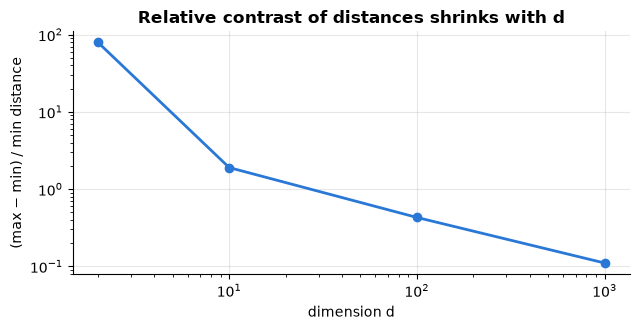

{2: np.float64(79.308), 10: np.float64(1.899), 100: np.float64(0.429), 1000: np.float64(0.11)}


In [18]:
# 1) Scaling: income in currency units swamps age in years
r9 = np.random.default_rng(9)
age = np.r_[r9.normal(25, 3, 200), r9.normal(60, 3, 200)]          # the real segments differ by age
income = r9.normal(50000, 15000, 400)                               # no segment signal, but huge numbers
Xs9 = np.c_[age, income]; ys9 = np.repeat([0, 1], 200)
raw = KMeans(2, n_init=5, random_state=0).fit_predict(Xs9)
scaled = KMeans(2, n_init=5, random_state=0).fit_predict(StandardScaler().fit_transform(Xs9))
print(f"k-means ARI on raw features: {adjusted_rand_score(ys9, raw):.2f} | after standardising: {adjusted_rand_score(ys9, scaled):.2f}")

# 2) Distance concentration: in high dimensions, nearest and farthest neighbours look alike
dims = [2, 10, 100, 1000]
contrast = []
for d in dims:
    P = r9.random((1000, d)); q = r9.random(d)
    dist = np.linalg.norm(P - q, axis=1)
    contrast.append((dist.max() - dist.min()) / dist.min())
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.loglog(dims, contrast, "o-"); ax.set_xlabel("dimension d"); ax.set_ylabel("(max − min) / min distance")
ax.set_title("Relative contrast of distances shrinks with d"); plt.tight_layout(); plt.show()
print({d: round(c, 3) for d, c in zip(dims, contrast)})

**What just happened?** Without scaling, income (tens of thousands) dominates the Euclidean distance, and k-means splits on income noise (ARI near 0). After standardising, it finds the two age groups perfectly (ARI = 1.00). In the second experiment, the gap between the nearest and the farthest of 1000 uniform points shrinks dramatically as the dimension grows: in 1000-D almost every point is about equally far away, so "nearest neighbour" carries little information (the **curse of dimensionality**; see also [`22_ML_System_Design/05_vector_databases`](../../22_ML_System_Design/05_vector_databases.ipynb)).

**Recipe**

| Step | Do | Why |
|---|---|---|
| 1. Represent | numeric: standardise or robust-scale; text/images: use embeddings; categorical: one-hot or Gower distance, or k-modes | the distance must reflect similarity you care about |
| 2. Reduce | PCA to ~10–50 dims (or UMAP for density methods) before clustering high-dimensional data | fights distance concentration and noise |
| 3. Choose distance | Euclidean for dense numeric; **cosine** for embeddings/text (normalise vectors, then Euclidean ≈ cosine); Jaccard for sets | |
| 4. Choose algorithm | blobs → k-means/GMM; arbitrary shapes + noise → HDBSCAN/DBSCAN; graph-like → spectral; need a hierarchy → agglomerative | Section 10 |
| 5. Validate | internal criteria, stability, a labelled audit sample (ARI), and **domain review** of cluster profiles | clusters are hypotheses, not facts |

## 10. Algorithm comparison

> 💬 **In plain English:** a one-page cheat sheet of which method suits which data.

| Algorithm | Needs k? | Cluster shapes | Handles noise? | Time (typical) | Memory | Scales to |
|---|---|---|---|---|---|---|
| k-means (Lloyd) | yes | convex, similar size | no | O(N·k·d) per iteration | O(N + k·d) | millions (mini-batch: more) |
| GMM (EM) | yes | ellipsoids, soft assignment | no | O(N·k·d²) per iteration | O(N·k) | ~10⁵–10⁶ |
| Agglomerative | no (cut the tree) | depends on linkage | no | O(N²)–O(N³) | O(N²) | ~10⁴ |
| DBSCAN | no (ε, min_samples) | arbitrary | **yes** | ~O(N log N), worst O(N²) | O(N) with an index | ~10⁶ in low dims |
| HDBSCAN | no (min_cluster_size) | arbitrary, varying density | **yes** | ~O(N log N), worst O(N²) | O(N) | ~10⁶ in low dims |
| Spectral | yes | arbitrary (graph-connected) | no | O(N³) dense, less if sparse | O(N²) dense | ~10⁴ dense |

| Embedding method | Linear? | Preserves | New points? | Typical use |
|---|---|---|---|---|
| PCA / classical MDS | yes | global variance / distances | yes | preprocessing, compression |
| ICA | yes | independence (non-Gaussianity) | yes | signal separation (EEG, audio) |
| NMF | yes (non-negative) | additive parts | yes (solve for W) | topics, spectra, recommenders |
| Isomap | no | geodesic distances | approx. | unrolling smooth manifolds |
| LLE | no | local linear structure | approx. | smooth manifolds |
| t-SNE | no | local neighbourhoods | no | visualisation only |
| UMAP | no | local + some global structure | yes | visualisation, preprocessing for HDBSCAN |

## 11. 🔗 How this connects to modern AI

- **Vector search**: inverted-file (IVF) indexes in FAISS and vector databases run **k-means** on embeddings to build coarse "buckets", and **product quantisation** runs k-means on sub-vectors ([`22_ML_System_Design/05_vector_databases`](../../22_ML_System_Design/05_vector_databases.ipynb)).
- **Training-data curation for LLMs**: semantic deduplication clusters document embeddings with k-means and removes near-duplicates within each cluster; clustering is also used to balance data mixtures.
- **Topic discovery**: BERTopic-style pipelines embed documents, reduce with UMAP and cluster with **HDBSCAN**, then name clusters with an LLM ([`07_NLP/07_topic_modeling`](../../07_NLP/07_topic_modeling.ipynb)).
- **VQ-VAEs and audio/image tokenisers** learn a codebook that is essentially online k-means in latent space; the discrete codes become tokens for transformers.
- **Graph learning**: spectral clustering's Laplacian eigenvectors are used as positional encodings in graph transformers, and GNN message passing is related to Laplacian smoothing ([`05_Deep_Learning/07_gnn`](../../05_Deep_Learning/07_gnn.ipynb)).
- **Interpretability**: t-SNE/UMAP maps of embeddings and NMF/ICA-style decompositions of activations (sparse dictionary learning) are standard tools for inspecting what neural networks represent.

## 12. Recap

- **Lloyd's k-means** alternates assignment and mean updates, always terminates, but only at a local minimum; **k-means++** seeding and restarts fix most bad starts; **mini-batch** trades a little inertia for speed. Cost O(N·k·d) per iteration.
- Choose k with several signals: **elbow, silhouette, gap statistic, Davies–Bouldin**, plus **bootstrap stability**; they agree only when structure is clear.
- **Hierarchical** clustering with **Lance–Williams** updates: single (chains, non-convex shapes), complete/average/Ward (compact). Read dendrograms by the largest vertical gap.
- **DBSCAN** (core/border/noise) finds arbitrary shapes and outliers but struggles with varying density; **OPTICS** and **HDBSCAN** handle it.
- **Spectral clustering** = kNN graph → normalised Laplacian → bottom eigenvectors → k-means; the number of zero eigenvalues = number of connected components.
- Prefer **ARI** over purity (gamed by many clusters) and raw NMI (biased upwards for many clusters).
- **ICA** separates independent non-Gaussian sources; **MDS = PCA** on Euclidean distances; **Isomap** (geodesic distances) and **LLE** (local weights) unroll manifolds; **t-SNE** sizes and gaps are not meaningful; **NMF** gives additive parts.
- Always **scale features**, reduce dimension before clustering high-dimensional data, and choose the distance deliberately.

## Practice problems

**1. (Easy, by hand)** Run k-means on the 1-D points 1, 2, 4, 7, 8, 10 with k = 2 and starting centres 1 and 10. Give the final centres and inertia.
<details><summary>Show solution</summary>

First assignment: {1, 2, 4} and {7, 8, 10} (4 is 3 from 1 and 6 from 10; 7 is 6 from 1 and 3 from 10). New centres 7/3 ≈ 2.333 and 25/3 ≈ 8.333. Reassigning changes nothing, so it stops. Inertia = (1.778 + 0.111 + 2.778) × 2 = **28/3 ≈ 9.333**.
```python
import numpy as np
x = np.array([1, 2, 4, 7, 8, 10], float)
c = np.array([1.0, 10.0])
for _ in range(10):
    lab = np.abs(x[:, None] - c).argmin(1)
    c_new = np.array([x[lab == j].mean() for j in range(2)])
    if np.allclose(c_new, c):
        break
    c = c_new
inertia = ((x - c[lab]) ** 2).sum()
```

</details>

**2. (Easy, conceptual)** Why does Lloyd's algorithm always terminate, and why can two runs give different answers?
<details><summary>Show solution</summary>

Each assignment step and each update step can only lower (or keep) the inertia, and whenever the partition changes the inertia strictly decreases (with a consistent tie-breaking rule). There are finitely many partitions of N points into k groups, so no partition can repeat and the algorithm stops. It stops at a **local** minimum that depends on the starting centres, so different initialisations can give different final partitions and inertias.

</details>

**3. (Easy, conceptual)** You have elongated, snake-like clusters with no noise. Which linkage would you choose, and what is the danger if a few noise points lie between clusters?
<details><summary>Show solution</summary>

**Single linkage**, because it merges by nearest neighbours and follows long, curved shapes. The danger is **chaining**: a thin line of noise points between two clusters lets single linkage merge them (Section 3, bridged blobs). Remedies: remove noise first (e.g. DBSCAN core points only), or use HDBSCAN, which is essentially a robust single linkage.

</details>

**4. (Medium, coding)** Implement **k-medoids** (alternating version), where each centre must be an actual data point. Why would you prefer it to k-means?
<details><summary>Show solution</summary>

```python
import numpy as np
def kmedoids(X, k, n_iter=100, seed=0):
    """Alternating (Voronoi-iteration) k-medoids: centres are actual data points."""
    rng = np.random.default_rng(seed)
    D = np.linalg.norm(X[:, None] - X[None], axis=2)          # any dissimilarity works
    medoids = rng.choice(len(X), k, replace=False)
    for _ in range(n_iter):
        labels = D[:, medoids].argmin(1)
        new = np.array([np.flatnonzero(labels == j)[D[np.ix_(labels == j, labels == j)].sum(1).argmin()]
                        for j in range(k)])                   # the member with least total distance
        if set(new) == set(medoids):
            break
        medoids = new
    return medoids, D[:, medoids].argmin(1)
```
It works with **any** dissimilarity (edit distance, Gower, DTW), not just squared Euclidean, because it never computes a mean; and it is more robust to outliers. The cost is O(N²) memory for the distance matrix. On three blobs, the best of 5 starts recovers the true clusters with ARI > 0.95.

</details>

**5. (Medium, coding)** Using the graph Laplacian, write a function that returns the number of connected components of a networkx graph, and check it on the disjoint union of a path, a cycle and a triangle.
<details><summary>Show solution</summary>

```python
import numpy as np
import networkx as nx
def n_components_from_laplacian(G, tol=1e-9):
    L = nx.laplacian_matrix(G).toarray().astype(float)       # unnormalised L = D - A
    return int((np.linalg.eigvalsh(L) < tol).sum())
```
The unnormalised Laplacian `L = D − A` is positive semi-definite and `xᵀLx = Σ_(i,j)∈E (xᵢ − xⱼ)²`, which is 0 exactly when x is constant on every connected component. So the null space has one dimension per component.

</details>

**6. (Medium, conceptual)** A colleague shows a t-SNE plot with one big, spread-out cluster and one small, tight cluster far to the left, and concludes "segment B is twice as diverse as segment A and very different from it". What would you say?
<details><summary>Show solution</summary>

Neither conclusion follows from t-SNE. t-SNE adapts its bandwidth per point so that each point has about `perplexity` effective neighbours, which equalises apparent cluster density and size; and it only tries to preserve local neighbourhoods, so distances between clusters are not to scale. Check diversity with within-cluster distances in the original (or PCA) space, check separation with between-cluster distances or a classifier, and repeat t-SNE with several perplexities and seeds.

</details>

**7. (Hard, coding)** Implement Tibshirani's gap-statistic decision rule as a function of the gap values and their standard errors.
<details><summary>Show solution</summary>

```python
def choose_k_gap(gaps, sds):
    """Tibshirani's rule: smallest k with Gap(k) >= Gap(k+1) - s_{k+1}. Lists are indexed from k = 1."""
    for k in range(1, len(gaps)):
        if gaps[k - 1] >= gaps[k] - sds[k]:
            return k
    return len(gaps)
```

</details>

**8. (Hard, project)** Cluster the sklearn digits (64-D) without using labels: compare k-means on raw pixels, k-means on PCA(20), spectral clustering on a kNN graph, and HDBSCAN on a 10-D embedding; report ARI against the true digits and the stability across seeds. Which representation matters more, the algorithm or the features?
<details><summary>Show solution</summary>

A typical outcome (checked with sklearn, 10 clusters): k-means on raw pixels gives ARI ≈ 0.67 and is very stable across seeds; k-means on PCA(20) is about the same (≈ 0.67); spectral clustering on a 10-nearest-neighbour graph does clearly better (≈ 0.76), because digit classes are connected along curved manifolds; HDBSCAN on a good low-dimensional embedding (e.g. UMAP) can do well too, but labels some points as noise. The lesson is that the **representation and the distance** often matter more than the choice between algorithms; in practice, clustering learned embeddings beats clustering raw features.

</details>

## Further reading
- Hastie, Tibshirani & Friedman, *The Elements of Statistical Learning* (2nd ed.), ch. 14 (unsupervised learning). Free PDF from the authors.
- Tan, Steinbach, Karpatne & Kumar, *Introduction to Data Mining* (2nd ed.), ch. 7–8 (cluster analysis).
- U. von Luxburg (2007), "A Tutorial on Spectral Clustering", *Statistics and Computing*.
- Arthur & Vassilvitskii (2007), "k-means++: the advantages of careful seeding"; Tibshirani, Walther & Hastie (2001), "Estimating the number of clusters via the gap statistic".
- Hyvärinen & Oja (2000), "Independent component analysis: algorithms and applications", *Neural Networks*.
- Wattenberg, Viégas & Johnson (2016), "How to Use t-SNE Effectively", *Distill* (free, interactive).
- scikit-learn user guide: "Clustering" and "Manifold learning" chapters.

## Next notebook
⬅️ Previous: [EM, variational inference and sampling](../17_probabilistic_graphical_models/02_em_variational_inference_and_sampling.ipynb) · ➡️ Next: [Neural and sequential recommenders](../09_recommendation_systems/03_neural_and_sequential_recommenders.ipynb)